In [3]:
import numpy as np
from skimage import io
import pandas as pd

def analizza_canale(percorso_file, nome_canale):
    """
    Legge un'immagine TIF in scala di grigi e calcola le metriche quantitative
    (Contrasto e SNR) utilizzando un approccio basato sui percentili.
    
    METODOLOGIA:
    Per evitare l'appiattimento dei dati causato da medie globali, questo
    algoritmo simula l'estrazione mirata di Region of Interest (ROI):
    - Il Target (Segnale) viene estratto dal 5% dei pixel più luminosi (>95° percentile),
      garantendo di misurare solo i fluorofori a fuoco e massima espressione.
    - Il Background (Fondo) viene estratto dal 20% dei pixel più scuri (<20° percentile),
      garantendo di misurare il vero rumore del PMT senza inquinamento da aloni.
    """
    
    try:
        immagine = io.imread(percorso_file)
    except FileNotFoundError:
        return {"Canale": nome_canale, "Errore": "File non trovato"}

    # Trasforma l'immagine 2D in una lista piatta di numeri (necessario per i percentili)
    img_array = np.array(immagine, dtype=float).flatten()
    
    # 1. Definizione delle Soglie Statistiche (Percentili)
    soglia_alta = np.percentile(img_array, 95)  # Trova il limite del top 5%
    soglia_bassa = np.percentile(img_array, 20) # Trova il limite del bottom 20%
    
    # 2. Estrazione selettiva dei pixel
    pixel_segnale = img_array[img_array > soglia_alta]
    pixel_background = img_array[img_array < soglia_bassa]
    
    # Controllo di sicurezza: se l'immagine e' completamente nera/vuota
    if len(pixel_segnale) == 0 or len(pixel_background) == 0:
        return {"Canale": nome_canale, "Errore": "Immagine anomala/vuota"}

    # 3. Calcolo delle grandezze statistiche fondamentali
    I_t = np.mean(pixel_segnale)
    I_b = np.mean(pixel_background)
    sigma_b = np.std(pixel_background)
    
    # 4. Calcolo di Contrasto (Weber) e SNR
    contrasto_weber = (I_t - I_b) / I_b if I_b > 0 else np.nan
    snr = (I_t - I_b) / sigma_b if sigma_b > 0 else np.nan
    
    return {
        "Canale": nome_canale,
        "I_t (Segnale)": round(I_t, 2),
        "I_b (Fondo)": round(I_b, 2),
        "Sigma_b (Dev Fondo)": round(sigma_b, 4),
        "Contrasto": round(contrasto_weber, 2),
        "SNR": round(snr, 2)
    }

# --- ESECUZIONE PRINCIPALE (MAIN) ---
file_canali = {
    "Membrane (Rosso - 600nm)": "/Users/francesco/Repositories /CNR_SNR_3channels/150mic_10ripetizioni_50mW_512px_770nm_Ch3.tif",
    "Citoplasma (Green - 488nm)": "/Users/francesco/Repositories /CNR_SNR_3channels/150mic_10ripetizioni_50mW_512px_770nm_Ch2.tif",
    "DAPI (Blu - 450nm)": "/Users/francesco/Repositories /CNR_SNR_3channels/150mic_10ripetizioni_50mW_512px_770nm_Ch1.tif"
}

risultati = []

for nome, percorso in file_canali.items():
    dati = analizza_canale(percorso, nome)
    risultati.append(dati)

df_risultati = pd.DataFrame(risultati)
print("\n=== RISULTATI ANALISI QUANTITATIVA DELLE IMMAGINI ===")
print(df_risultati.to_string(index=False))





=== RISULTATI ANALISI QUANTITATIVA DELLE IMMAGINI ===
                    Canale  I_t (Segnale)  I_b (Fondo)  Sigma_b (Dev Fondo)  Contrasto   SNR
  Membrane (Rosso - 600nm)          26.35         1.25               0.7521      20.12 33.38
Citoplasma (Green - 488nm)          45.77         1.26               1.0683      35.22 41.66
        DAPI (Blu - 450nm)          21.19         2.34               1.3413       8.05 14.05


- Immagini caricate correttamente.
- Analisi ROI statica in corso: [Y: 128:384, X: 128:384]


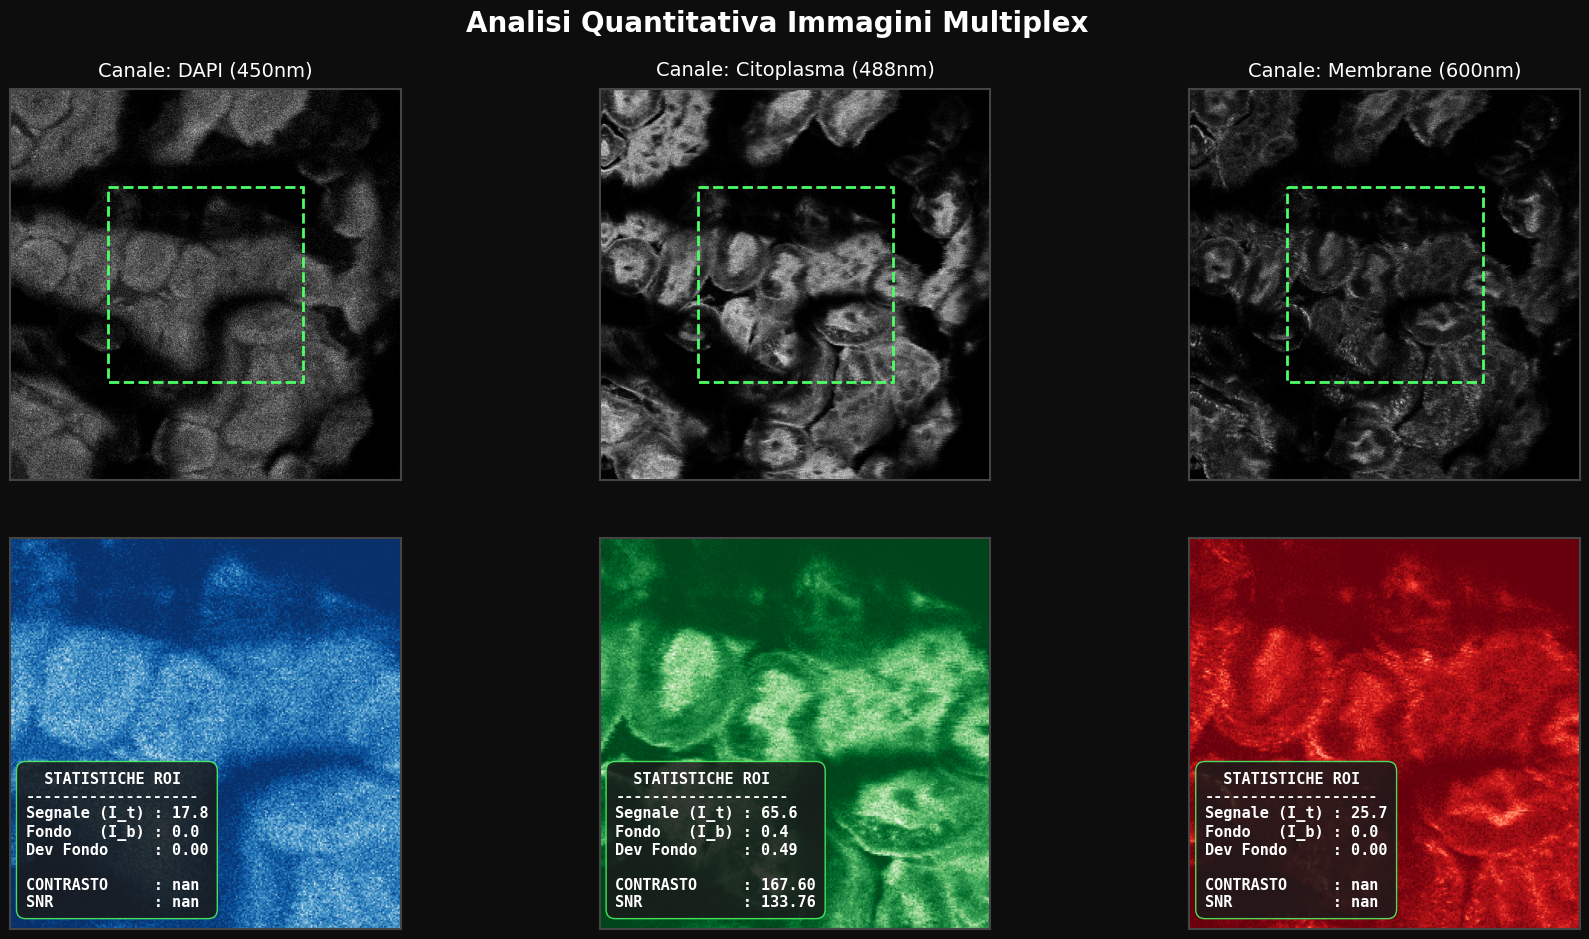

In [4]:
# %% [markdown]
# # Analisi Quantitativa Multiplex: SNR e Contrasto (ROI Statica)
# Pipeline: Ritaglio da coordinate → Calcolo Percentili → Dashboard Risultati
# %%

import numpy as np
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec
from matplotlib.patches import Rectangle
from skimage import io
import os
from pathlib import Path

# ── 0. Configurazione Parametri ──────────────────────────────────────────────
CONFIG = {
    # Percorsi dei file (assicurati che non ci siano spazi vuoti strani)
    "folder_path": "/Users/francesco/Repositories /CNR_SNR_3channels",
    
    # Nomi file
    "file_ch1": "300mic_5ripetizioni_50mW_512px_800nm_Ch1.tif", # DAPI
    "file_ch2": "300mic_5ripetizioni_50mW_512px_800nm_Ch2.tif", # Verde
    "file_ch3": "300mic_5ripetizioni_50mW_512px_800nm_Ch3.tif", # Rosso
    
    # Etichette Canali
    "nomi_canali": ["DAPI (450nm)", "Citoplasma (488nm)", "Membrane (600nm)"],
    
    # --- COORDINATE DELLA ROI ---
    # Immagine 512x512 -> Qui prendiamo il quadrato centrale 256x256
    "roi_ymin": 128,  # Riga di partenza (alto)
    "roi_ymax": 384,  # Riga di fine (basso)
    "roi_xmin": 128,  # Colonna di partenza (sinistra)
    "roi_xmax": 384,  # Colonna di fine (destra)
    
    # Colormaps per i singoli canali nella dashboard
    "cmap_ch1": "Blues_r",  
    "cmap_ch2": "Greens_r",
    "cmap_ch3": "Reds_r",
    "cmap_raw": "gray"
}
# ────────────────────────────────────────────────────────────────────────────

def analizza_roi(immagine, roi_coords):
    """Calcola Contrasto e SNR basato sui percentili 95 (segnale) e 20 (fondo)."""
    ymin, ymax, xmin, xmax = roi_coords
    roi_img = immagine[ymin:ymax, xmin:xmax]
    img_array = np.array(roi_img, dtype=float).flatten()
    
    soglia_alta = np.percentile(img_array, 95)
    soglia_bassa = np.percentile(img_array, 20)
    
    pixel_segnale = img_array[img_array > soglia_alta]
    pixel_background = img_array[img_array < soglia_bassa]
    
    if len(pixel_segnale) == 0 or len(pixel_background) == 0:
        return roi_img, (np.nan, np.nan, np.nan, np.nan, np.nan)

    I_t = np.mean(pixel_segnale)
    I_b = np.mean(pixel_background)
    sigma_b = np.std(pixel_background)
    
    contrasto = (I_t - I_b) / I_b if I_b > 0 else np.nan
    snr = (I_t - I_b) / sigma_b if sigma_b > 0 else np.nan
    
    return roi_img, (I_t, I_b, sigma_b, contrasto, snr)

# %% [markdown]
# ## 1. Lettura File e Controllo
# %%
os.chdir(CONFIG["folder_path"])
lista_file = [CONFIG["file_ch1"], CONFIG["file_ch2"], CONFIG["file_ch3"]]
immagini = []

for fname in lista_file:
    p = Path(fname)
    if not p.exists():
        raise FileNotFoundError(f"! Impossibile trovare il file: {p.absolute()}")
    immagini.append(io.imread(p))

print("- Immagini caricate correttamente.")

# %% [markdown]
# ## 2. Elaborazione ROI
# %%
ymin, ymax = CONFIG["roi_ymin"], CONFIG["roi_ymax"]
xmin, xmax = CONFIG["roi_xmin"], CONFIG["roi_xmax"]
h_roi, w_roi = (ymax - ymin), (xmax - xmin)
coords = (ymin, ymax, xmin, xmax)

print(f"- Analisi ROI statica in corso: [Y: {ymin}:{ymax}, X: {xmin}:{xmax}]")

risultati_dati = []
roi_ritagliate = []

for img in immagini:
    roi_img, stats = analizza_roi(img, coords)
    roi_ritagliate.append(roi_img)
    risultati_dati.append(stats)

# %% [markdown]
# ## 3. Generazione Dashboard Stile Olografia
# %%
fig = plt.figure(figsize=(18, 10), facecolor="#0d0d0d")
fig.suptitle("Analisi Quantitativa Immagini Multiplex", color="white", fontsize=20, fontweight="bold", y=0.96)

gs = gridspec.GridSpec(2, 3, figure=fig, hspace=0.15, wspace=0.15,
                       left=0.04, right=0.98, top=0.88, bottom=0.04)

colormaps_crop = [CONFIG["cmap_ch1"], CONFIG["cmap_ch2"], CONFIG["cmap_ch3"]]

for i in range(3):
    # ─── Riga 0: Immagini Grezze con bounding box ROI ───
    ax_raw = fig.add_subplot(gs[0, i])
    ax_raw.imshow(immagini[i], cmap=CONFIG["cmap_raw"], origin="upper")
    ax_raw.set_title(f"Canale: {CONFIG['nomi_canali'][i]}", color="white", fontsize=14, pad=10)
    
    # Disegna il rettangolo della ROI
    rect = Rectangle((xmin, ymin), w_roi, h_roi, linewidth=2, edgecolor='#4dff65', facecolor='none', linestyle='--')
    ax_raw.add_patch(rect)
    
    # ─── Riga 1: Gated ROI (Ritagli) con box statistiche ───
    ax_crop = fig.add_subplot(gs[1, i])
    ax_crop.imshow(roi_ritagliate[i], cmap=colormaps_crop[i], origin="upper")
    
    I_t, I_b, sigma_b, contrasto, snr = risultati_dati[i]
    
    # Testo formattato
    stats_text = (
        f"  STATISTICHE ROI  \n"
        f"-------------------\n"
        f"Segnale (I_t) : {I_t:.1f}\n"
        f"Fondo   (I_b) : {I_b:.1f}\n"
        f"Dev Fondo     : {sigma_b:.2f}\n\n"
        f"CONTRASTO     : {contrasto:.2f}\n"
        f"SNR           : {snr:.2f}"
    )
    
    ax_crop.text(0.04, 0.05, stats_text, transform=ax_crop.transAxes,
                 color="white", fontsize=11, va="bottom", fontfamily="monospace", fontweight="bold",
                 bbox=dict(facecolor="#1a1a1a", edgecolor="#4dff65", boxstyle="round,pad=0.6", alpha=0.85))

# Formattazione degli assi
for ax in fig.axes:
    ax.set_xticks([])
    ax.set_yticks([])
    for spine in ax.spines.values():
        spine.set_edgecolor("#444444")
        spine.set_linewidth(1.5)

plt.show()

- Estrazione della slice Z=12 dai file TIF in corso...
- Estrazione completata.
- Analisi ROI circolare: [Centro: (256, 256), Raggio: 100px]


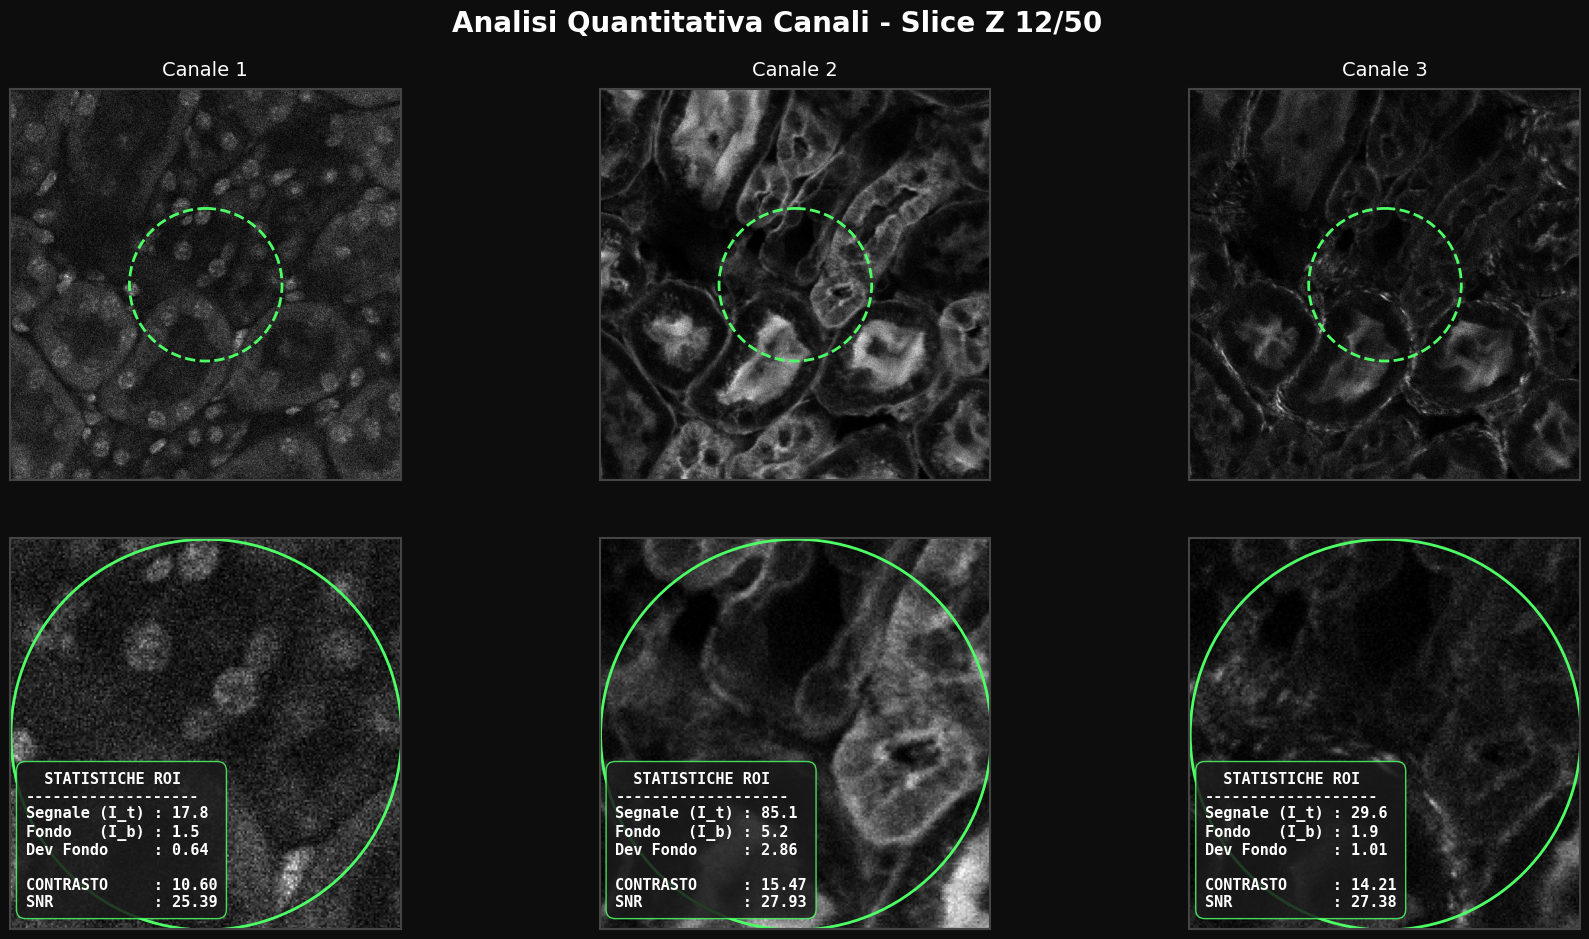

In [5]:
# %% [markdown]
# # Analisi Quantitativa Z-Stack: ROI Circolare
# Estrazione Slice Z -> Maschera Circolare -> Analisi Segnale/Fondo
# %%

import numpy as np
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec
from matplotlib.patches import Circle
from skimage import io
import os
from pathlib import Path

# ── 0. Configurazione Parametri ──────────────────────────────────────────────
CONFIG = {
    # Percorsi dei file
    "folder_path": "/Users/francesco/Repositories /CNR_SNR_3channels",
    
    # Nomi file (Z-stacks da 50 slice)
    "file_ch1": "zstack_150mic_50piani_10ripetizioni_50mW_512px_770nm_Ch1.tif",
    "file_ch2": "zstack_150mic_50piani_10ripetizioni_50mW_512px_770nm_Ch2.tif",
    "file_ch3": "zstack_150mic_50piani_10ripetizioni_50mW_512px_770nm_Ch3.tif",
    
    "nomi_canali": ["Canale 1", "Canale 2", "Canale 3"],
    
    # --- IMPOSTAZIONI Z-STACK E VISUALIZZAZIONE ---
    "z_target": 11,       # Indice Python 11 corrisponde alla Z 12/50
    "cmap_visual": "gray", # Scala di grigi globale
    
    # --- COORDINATE ROI CIRCOLARE ---
    "roi_cx": 256,        # Coordinata X del centro
    "roi_cy": 256,        # Coordinata Y del centro
    "roi_r": 100          # Raggio del cerchio in pixel
}
# ────────────────────────────────────────────────────────────────────────────

def analizza_maschera_circolare(immagine_2d, cx, cy, r):
    """
    Applica una maschera circolare all'immagine 2D e calcola le metriche
    usando solo i pixel interni al cerchio.
    """
    h, w = immagine_2d.shape
    
    # 1. Creazione della maschera circolare booleana
    Y, X = np.ogrid[:h, :w]
    distanza_dal_centro = (X - cx)**2 + (Y - cy)**2
    maschera = distanza_dal_centro <= r**2
    
    # 2. Estrazione dei soli pixel interni alla ROI
    pixel_in_roi = immagine_2d[maschera]
    
    if len(pixel_in_roi) == 0:
        return None, (np.nan, np.nan, np.nan, np.nan, np.nan)

    # 3. Calcolo metriche sui percentili
    soglia_alta = np.percentile(pixel_in_roi, 95)
    soglia_bassa = np.percentile(pixel_in_roi, 20)
    
    pixel_segnale = pixel_in_roi[pixel_in_roi > soglia_alta]
    pixel_background = pixel_in_roi[pixel_in_roi < soglia_bassa]
    
    I_t = np.mean(pixel_segnale) if len(pixel_segnale) > 0 else np.nan
    I_b = np.mean(pixel_background) if len(pixel_background) > 0 else np.nan
    sigma_b = np.std(pixel_background) if len(pixel_background) > 0 else np.nan
    
    contrasto = (I_t - I_b) / I_b if I_b > 0 else np.nan
    snr = (I_t - I_b) / sigma_b if sigma_b > 0 else np.nan
    
    # 4. Estrazione crop visivo (bounding box attorno al cerchio)
    y_min, y_max = max(0, cy - r), min(h, cy + r)
    x_min, x_max = max(0, cx - r), min(w, cx + r)
    crop_img = immagine_2d[y_min:y_max, x_min:x_max]
    
    return crop_img, (I_t, I_b, sigma_b, contrasto, snr)

# %% [markdown]
# ## 1. Lettura Z-Stacks ed Estrazione Slice
# %%
os.chdir(CONFIG["folder_path"])
lista_file = [CONFIG["file_ch1"], CONFIG["file_ch2"], CONFIG["file_ch3"]]
immagini_z12 = []

print(f"- Estrazione della slice Z={CONFIG['z_target'] + 1} dai file TIF in corso...")

for fname in lista_file:
    p = Path(fname)
    if not p.exists():
        raise FileNotFoundError(f"! Impossibile trovare il file: {p.absolute()}")
    
    # Legge l'intero stack 3D (Z, Y, X)
    stack_3d = io.imread(p)
    
    # Controllo di sicurezza sulle dimensioni
    if stack_3d.ndim == 3:
        # Estrae la slice Z desiderata
        slice_2d = stack_3d[CONFIG["z_target"], :, :]
        immagini_z12.append(slice_2d)
    else:
        # Fallback se l'immagine fosse già 2D
        immagini_z12.append(stack_3d)

print("- Estrazione completata.")

# %% [markdown]
# ## 2. Elaborazione ROI Circolare
# %%
cx, cy, r = CONFIG["roi_cx"], CONFIG["roi_cy"], CONFIG["roi_r"]
print(f"- Analisi ROI circolare: [Centro: ({cx}, {cy}), Raggio: {r}px]")

risultati_dati = []
roi_ritagliate = []

for img in immagini_z12:
    crop, stats = analizza_maschera_circolare(img, cx, cy, r)
    roi_ritagliate.append(crop)
    risultati_dati.append(stats)

# %% [markdown]
# ## 3. Dashboard Risultati
# %%
fig = plt.figure(figsize=(18, 10), facecolor="#0d0d0d")
fig.suptitle(f"Analisi Quantitativa Canali - Slice Z {CONFIG['z_target'] + 1}/50", 
             color="white", fontsize=20, fontweight="bold", y=0.96)

gs = gridspec.GridSpec(2, 3, figure=fig, hspace=0.15, wspace=0.15,
                       left=0.04, right=0.98, top=0.88, bottom=0.04)

for i in range(3):
    # ─── Riga 0: Intera Slice (Gray) con indicatore ROI ───
    ax_raw = fig.add_subplot(gs[0, i])
    ax_raw.imshow(immagini_z12[i], cmap=CONFIG["cmap_visual"], origin="upper")
    ax_raw.set_title(f"{CONFIG['nomi_canali'][i]}", color="white", fontsize=14, pad=10)
    
    # Disegna il cerchio della ROI
    cerchio = Circle((cx, cy), r, linewidth=2, edgecolor='#4dff65', facecolor='none', linestyle='--')
    ax_raw.add_patch(cerchio)
    
    # ─── Riga 1: Crop della ROI con box statistiche ───
    ax_crop = fig.add_subplot(gs[1, i])
    ax_crop.imshow(roi_ritagliate[i], cmap=CONFIG["cmap_visual"], origin="upper")
    
    # Disegna il cerchio anche nel ritaglio (le coordinate locali sono semplicemente r, r)
    cerchio_crop = Circle((r, r), r, linewidth=2, edgecolor='#4dff65', facecolor='none', linestyle='-')
    ax_crop.add_patch(cerchio_crop)
    
    I_t, I_b, sigma_b, contrasto, snr = risultati_dati[i]
    
    # Testo formattato
    stats_text = (
        f"  STATISTICHE ROI  \n"
        f"-------------------\n"
        f"Segnale (I_t) : {I_t:.1f}\n"
        f"Fondo   (I_b) : {I_b:.1f}\n"
        f"Dev Fondo     : {sigma_b:.2f}\n\n"
        f"CONTRASTO     : {contrasto:.2f}\n"
        f"SNR           : {snr:.2f}"
    )
    
    ax_crop.text(0.04, 0.05, stats_text, transform=ax_crop.transAxes,
                 color="white", fontsize=11, va="bottom", fontfamily="monospace", fontweight="bold",
                 bbox=dict(facecolor="#1a1a1a", edgecolor="#4dff65", boxstyle="round,pad=0.6", alpha=0.85))

# Formattazione degli assi per eliminare la grafica superflua
for ax in fig.axes:
    ax.set_xticks([])
    ax.set_yticks([])
    for spine in ax.spines.values():
        spine.set_edgecolor("#444444")
        spine.set_linewidth(1.5)

plt.show()

## Analisi con ROI automatica dal Canale 1

In questa sezione la ROI non viene scelta manualmente o fissata a priori, ma viene determinata in modo automatico a partire dal **canale 1** (canale 1 BLU DAPI, canale 2 verde, canale 3 rosso). L'obiettivo e individuare una struttura piccola, luminosa e approssimativamente circolare, compatibile con un nucleo o con una regione nucleare ben definita.

L'idea e la seguente:
- si estrae una singola slice Z dallo stack
- nel canale 1 si cercano le regioni piu luminose in scala di grigi
- tra queste si seleziona la struttura piu plausibilmente nucleare, favorendo componenti compatte e quasi circolari
- si costruisce una ROI circolare centrata su quella struttura
- la stessa ROI viene poi applicata anche ai canali 2 e 3, cosi il confronto tra canali avviene sulla **stessa identica regione spaziale**

Questo approccio serve a rendere l'analisi piu coerente dal punto di vista biologico e quantitativo: invece di confrontare zone diverse tra i canali, si misura il segnale di tutti e tre nello stesso punto dell'immagine, prendendo come riferimento il target piu evidente nel canale 1.

Alla fine della cella verranno mostrati:
- la ROI rilevata sul canale 1
- la stessa ROI riportata sugli altri due canali
- i valori di $I_t$, $I_b$, $\sigma_b$, Contrasto e SNR per ciascun canale

In [6]:
#%pip install cellpose --break-system-packages


model_type argument is not used in v4.0.1+. Ignoring this argument...


- Starting Cellpose neural network (model_type='nuclei')...


channels deprecated in v4.0.1+. If data contain more than 3 channels, only the first 3 channels will be used
/opt/homebrew/lib/python3.14/site-packages/cellpose/dynamics.py:524: UserWarning: Sparse invariant checks are implicitly disabled. Memory errors (e.g. SEGFAULT) will occur when operating on a sparse tensor which violates the invariants, but checks incur performance overhead. To silence this warning, explicitly opt in or out. See `torch.sparse.check_sparse_tensor_invariants.__doc__` for guidance.  (Triggered internally at /Users/runner/work/pytorch/pytorch/pytorch/aten/src/ATen/Context.cpp:767.)
  coo = torch.sparse_coo_tensor(pt, torch.ones(pt.shape[1], device=pt.device, dtype=torch.int),


- Selected Nucleus: Center (X:40, Y:237) | ROI Radius: 22px

--- Quantitative Results ---


Channel,I_t (Signal),I_b (Bkg),Sigma_b,Contrast,SNR,CNR
"Blue (DAPI, Ch1)",21.75,3.69,1.21,4.89,17.98,14.93
Green (Ch2),72.11,4.59,1.36,14.73,53.14,49.76
Red (Ch3),21.16,1.48,0.66,13.32,32.30,30.04


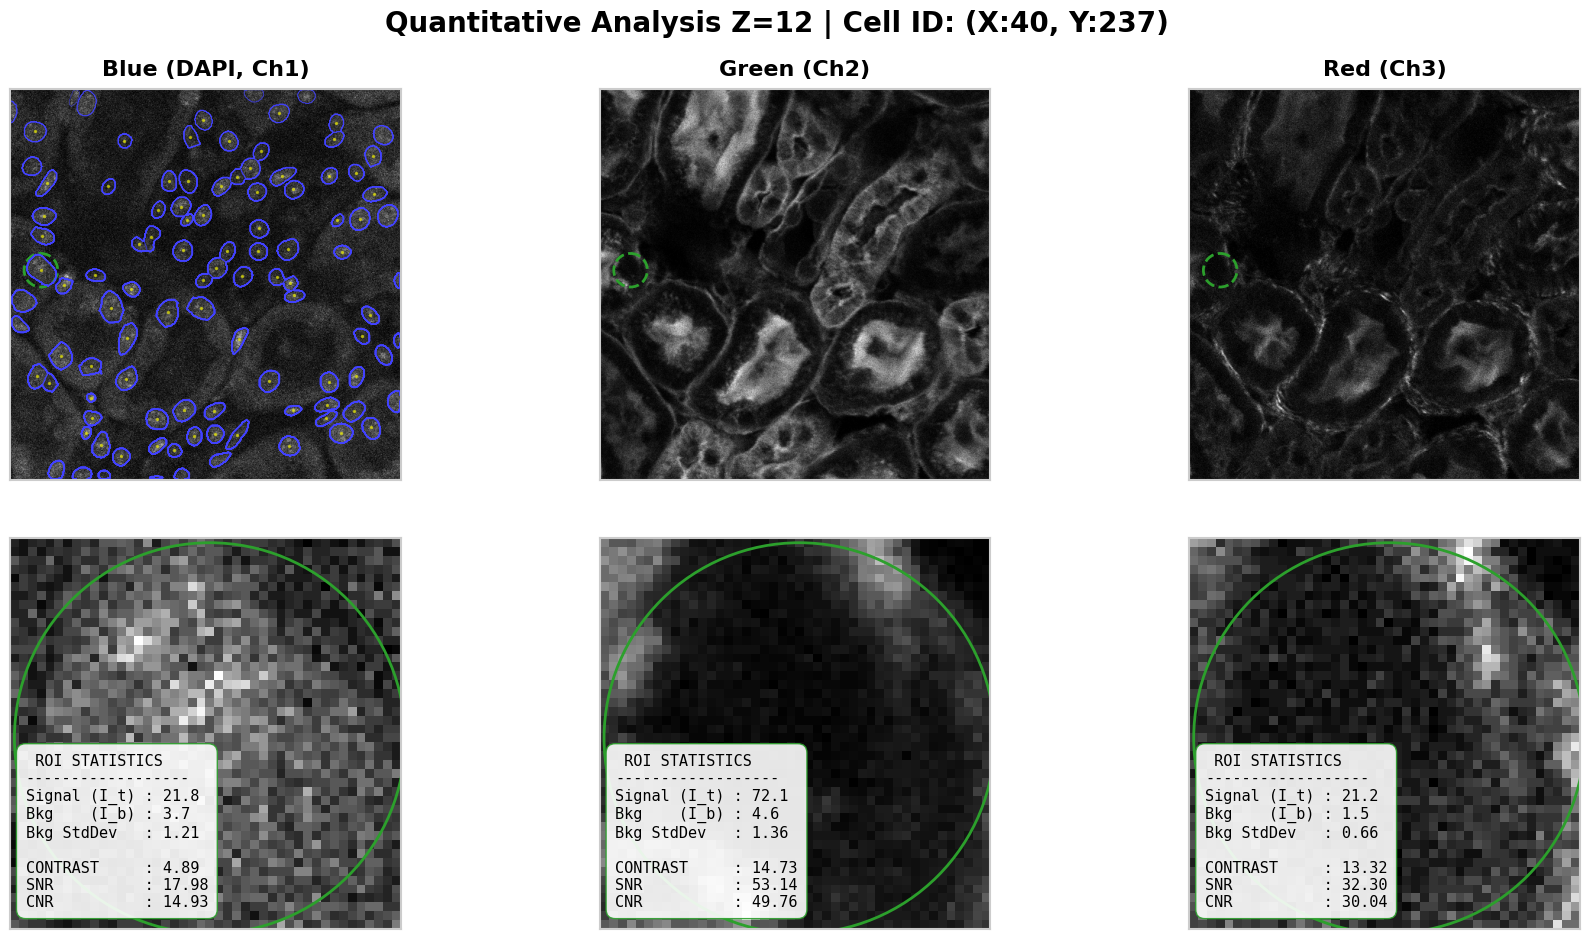

In [7]:
# %% [markdown]
# # Quantitative Z-Stack Analysis: Auto-detect ROI with CELLPOSE
# Pipeline: AI Segmentation (Cellpose) -> Filtering -> Multi-channel Analysis
# %%

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec
from matplotlib.patches import Circle
from skimage import io, measure
import os
from pathlib import Path

# Per il rendering professionale del DataFrame in Jupyter
from IPython.display import display 

# Importiamo il modello di Deep Learning
from cellpose import models

# -- 0. Configuration Parameters ------------------------------------------------
CONFIG = {
    "folder_path": "/Users/francesco/Repositories /CNR_SNR_3channels",
    "file_ch1": "zstack_150mic_50piani_10ripetizioni_50mW_512px_770nm_Ch1.tif",
    "file_ch2": "zstack_150mic_50piani_10ripetizioni_50mW_512px_770nm_Ch2.tif",
    "file_ch3": "zstack_150mic_50piani_10ripetizioni_50mW_512px_770nm_Ch3.tif",
    "nomi_canali": ["Blue (DAPI, Ch1)", "Green (Ch2)", "Red (Ch3)"],
    "z_target": 11,
    "cmap_visual": "gray",

    # -- ROI PARAMETERS --
    "roi_radius": 22,
    "bordo_sicurezza": 30
}

def estrai_slice_2d(stack, z_target):
    if stack.ndim == 3:
        z_index = min(max(z_target, 0), stack.shape[0] - 1)
        return stack[z_index, :, :]
    return stack

def trova_nucleo_con_ai(immagine_2d, config):
    """Usa Cellpose per individuare nuclei e seleziona quello piu prominente lontano dai bordi."""
    print("- Starting Cellpose neural network (model_type='nuclei')...")

    model = models.CellposeModel(gpu=False, model_type='nuclei')
    eval_result = model.eval(immagine_2d, diameter=None, channels=[0, 0])
    masks = eval_result[0] if isinstance(eval_result, tuple) else eval_result

    regioni = measure.regionprops(masks, intensity_image=immagine_2d)
    candidati = []

    h, w = immagine_2d.shape
    b = config["bordo_sicurezza"]

    for reg in regioni:
        cy, cx = reg.centroid

        if cy < b or cy > h - b or cx < b or cx > w - b:
            continue

        score = float(reg.area) * float(reg.intensity_mean)
        candidati.append({
            "cx": int(cx),
            "cy": int(cy),
            "score": score
        })

    if candidati:
        migliore = max(candidati, key=lambda item: item["score"])
        return migliore["cx"], migliore["cy"], config["roi_radius"], masks, candidati

    print("! WARNING: Cellpose did not find any valid nuclei.")
    return w // 2, h // 2, config["roi_radius"], masks, []

def analizza_maschera_circolare(immagine_2d, cx, cy, r):
    h, w = immagine_2d.shape
    y_grid, x_grid = np.ogrid[:h, :w]
    maschera = (x_grid - cx) ** 2 + (y_grid - cy) ** 2 <= r ** 2
    pixel_in_roi = np.asarray(immagine_2d, dtype=float)[maschera]

    if len(pixel_in_roi) == 0:
        return None, (np.nan, np.nan, np.nan, np.nan, np.nan, np.nan), None

    soglia_alta = np.percentile(pixel_in_roi, 95)
    soglia_bassa = np.percentile(pixel_in_roi, 20)
    pixel_segnale = pixel_in_roi[pixel_in_roi > soglia_alta]
    pixel_background = pixel_in_roi[pixel_in_roi < soglia_bassa]

    I_t = np.mean(pixel_segnale) if len(pixel_segnale) > 0 else np.nan
    I_b = np.mean(pixel_background) if len(pixel_background) > 0 else np.nan
    sigma_b = np.std(pixel_background) if len(pixel_background) > 0 else np.nan
    
    # Metriche
    contrasto = (I_t - I_b) / I_b if np.isfinite(I_b) and I_b > 0 else np.nan
    snr = I_t / sigma_b if np.isfinite(sigma_b) and sigma_b > 0 else np.nan
    cnr = (I_t - I_b) / sigma_b if np.isfinite(sigma_b) and sigma_b > 0 else np.nan

    y_min, y_max = max(0, cy - r), min(h, cy + r)
    x_min, x_max = max(0, cx - r), min(w, cx + r)
    crop_img = immagine_2d[y_min:y_max, x_min:x_max]

    return crop_img, (I_t, I_b, sigma_b, contrasto, snr, cnr), (cx - x_min, cy - y_min)

# %% [markdown]
# ## 1. Read Z-Stacks
# %%
os.chdir(CONFIG["folder_path"])
immagini_z = []

for fname in [CONFIG["file_ch1"], CONFIG["file_ch2"], CONFIG["file_ch3"]]:
    p = Path(fname)
    if not p.exists():
        raise FileNotFoundError(f"File not found: {p.absolute()}")
    stack = io.imread(p)
    immagini_z.append(estrai_slice_2d(stack, CONFIG["z_target"]))

# %% [markdown]
# ## 2. Cellpose Segmentation
# %%
cx, cy, r, maschera_ai, tutti_i_candidati = trova_nucleo_con_ai(immagini_z[0], CONFIG)
print(f"- Selected Nucleus: Center (X:{cx}, Y:{cy}) | ROI Radius: {r}px")

# %% [markdown]
# ## 3. Analysis & Dashboard
# %%
risultati_dati, roi_ritagliate, centri_locali = [], [], []

for nome, img in zip(CONFIG["nomi_canali"], immagini_z):
    crop, stats, c_loc = analizza_maschera_circolare(img, cx, cy, r)
    roi_ritagliate.append(crop)
    centri_locali.append(c_loc)
    risultati_dati.append((nome, *stats))

# Visualizzazione professionale della tabella
df_roi = pd.DataFrame(risultati_dati, columns=["Channel", "I_t (Signal)", "I_b (Bkg)", "Sigma_b", "Contrast", "SNR", "CNR"])
print("\n--- Quantitative Results ---")
# Applica arrotondamento a 2 decimali per la visualizzazione Jupyter
display(df_roi.style.format(precision=2, na_rep="NaN").hide(axis="index"))

# Creazione Dashboard (Sfondo Bianco)
fig = plt.figure(figsize=(18, 10), facecolor="white")
fig.suptitle(f"Quantitative Analysis Z={CONFIG['z_target'] + 1} | Cell ID: (X:{cx}, Y:{cy})", color="black", fontsize=20, fontweight="bold", y=0.96)
gs = gridspec.GridSpec(2, 3, figure=fig, hspace=0.15, wspace=0.15, left=0.04, right=0.98, top=0.88, bottom=0.04)

livelli_maschera = np.unique(maschera_ai)
livelli_maschera = livelli_maschera[livelli_maschera > 0]

for i in range(3):
    # Riga superiore (Raw)
    ax_raw = fig.add_subplot(gs[0, i])
    ax_raw.imshow(immagini_z[i], cmap=CONFIG["cmap_visual"], origin="upper")
    ax_raw.set_title(CONFIG["nomi_canali"][i], color="black", fontsize=16, fontweight="bold", pad=10)

    if i == 0 and len(livelli_maschera) > 0:
        ax_raw.contour(maschera_ai, levels=livelli_maschera, colors=["#4444ff"], linewidths=0.5, alpha=0.6)
        for cand in tutti_i_candidati:
            ax_raw.plot(cand["cx"], cand["cy"], marker='.', color='yellow', markersize=3, alpha=0.5)

    ax_raw.add_patch(Circle((cx, cy), r, linewidth=2, edgecolor="#2ca02c", facecolor="none", linestyle="--"))

    # Riga inferiore (Crop)
    ax_crop = fig.add_subplot(gs[1, i])
    ax_crop.imshow(roi_ritagliate[i], cmap=CONFIG["cmap_visual"], origin="upper")
    ax_crop.add_patch(Circle(centri_locali[i], r, linewidth=2, edgecolor="#2ca02c", facecolor="none"))

    _, I_t, I_b, sigma_b, contrasto, snr, cnr = risultati_dati[i]
    
    stats_text = (f" ROI STATISTICS \n"
                  f"------------------\n"
                  f"Signal (I_t) : {I_t:.1f}\n"
                  f"Bkg    (I_b) : {I_b:.1f}\n"
                  f"Bkg StdDev   : {sigma_b:.2f}\n\n"
                  f"CONTRAST     : {contrasto:.2f}\n"
                  f"SNR          : {snr:.2f}\n"
                  f"CNR          : {cnr:.2f}")
    
    # Box statistico con stile aggiornato per sfondo chiaro
    ax_crop.text(0.04, 0.05, stats_text, transform=ax_crop.transAxes, 
                 color="black", fontsize=11, va="bottom", fontfamily="monospace", 
                 bbox=dict(facecolor="white", edgecolor="#2ca02c", boxstyle="round,pad=0.6", alpha=0.9))

for ax in fig.axes:
    ax.set_xticks([])
    ax.set_yticks([])
    for spine in ax.spines.values():
        spine.set_edgecolor("#cccccc")
        spine.set_linewidth(1.5)

plt.show()

In [8]:
"pivot_mode": "manual_label",
"pivot_label": 7,

SyntaxError: illegal target for annotation (1972420204.py, line 1)

## Analisi con ROI pivot e background locale esterno

Questa sezione estende l'analisi della cella precedente aggiungendo due idee pratiche:
- puoi scegliere un **nucleo pivot** manualmente oppure lasciarlo scegliere automaticamente al codice
- il **background (BG)** non viene preso dentro la ROI del segnale, ma da una **ROI esterna vicina**, scura e senza interferenze

### Idea biologica e quantitativa

L'obiettivo e misurare il segnale di uno stesso punto biologico nei tre canali usando:
- una **ROI di segnale** centrata su un nucleo pivot
- una **ROI di background** vicina ma esterna, usata come riferimento locale del fondo

Questo approccio e piu robusto del percentile basso interno alla stessa ROI, perche separa meglio:
- il **segnale biologico**
- il **fondo locale** dovuto a rumore, offset, autofluorescenza residua e haze strumentale

In modo intuitivo, la logica implementata e:
- prima scegli **chi** vuoi studiare (il nucleo pivot), poi scegli **contro cosa** lo confronti (il fondo locale migliore)
- il pivot e la stessa regione biologica sui tre canali, mentre il BG viene adattato per ogni canale dove il segnale e minimo e il fondo e piu uniforme

### Cosa significano le metriche

- **BG / I_b**: intensita media nella ROI di background locale. E la stima del fondo locale nel canale.
- **Sigma_b**: deviazione standard del background. Misura quanto il fondo e rumoroso o instabile.
- **I_t**: intensita media del segnale, qui stimata come media dei pixel sopra il 95 percentile dentro la ROI di segnale.
- **Contrasto**: $(I_t - I_b) / I_b$. Dice quanto il segnale emerge rispetto al fondo medio.
- **SNR**: $I_t / \sigma_b$. Misura quanto il segnale e grande rispetto alla variabilita del fondo.
- **CNR**: $(I_t - I_b) / \sigma_b$. Misura quanto il segnale corretto per il fondo supera il rumore del background.

In pratica:
- se **I_b** aumenta, il fondo locale e piu alto
- se **Sigma_b** aumenta, il fondo e piu rumoroso
- se **SNR** e **CNR** aumentano, il segnale e piu distinguibile

### Come viene scelto il pivot

La cella supporta la scelta manuale del pivot in modo allineato alla visualizzazione numerata:
- in Step 1 i nuclei sono ordinati e numerati per **Rank** sull'immagine Blue (DAPI, Ch1)
- in Step 2 puoi scegliere il pivot con `selection_mode = "rank"`, `"click"` o `"label"`
- con la modalita **rank** il codice converte esplicitamente `Rank -> Label`, evitando ambiguita tra numero visualizzato e label di segmentazione

### Come viene scelto il background

Il background viene cercato automaticamente come una ROI circolare che:
- sia abbastanza vicina al pivot
- non intersechi il nucleo pivot
- non cada sopra altre maschere segmentate
- sia il piu possibile **scura e omogenea**

Inoltre, la scelta del BG e **per-canale**:
- per Blue, Green e Red viene cercata una ROI locale separata
- ogni canale ottiene quindi il proprio `I_b` e la propria `Sigma_b`, piu coerenti con il suo fondo reale

### Come usare la cella

1. In Step 1 guarda la mappa nuclei numerata e identifica il nucleo da analizzare.
2. In Step 2 imposta `MANUAL_PIVOT["selection_mode"] = "rank"` e `MANUAL_PIVOT["pivot_rank"]` per selezionarlo in modo diretto.
3. In alternativa usa `selection_mode = "click"` oppure `"label"` se preferisci una selezione visuale o per etichetta.
4. Lascia `bg_mode = "auto"` per cercare automaticamente il BG migliore su ciascun canale.
5. Se la ROI di background cade in una zona non convincente, modifica i parametri: `bg_radius`, `bg_search_rmin`, `bg_search_rmax`, `bg_exclusion_margin`.

### Lettura pratica dell'output

La dashboard mostra per ogni canale:
- immagine intera con ROI del pivot e ROI di background
- crop della ROI di segnale con le metriche
- crop della ROI di background locale

Questa sezione e utile quando vuoi decidere tu **quale nucleo confrontare tra i canali**, mantenendo automatico, locale e coerente il calcolo del fondo in ogni canale.

model_type argument is not used in v4.0.1+. Ignoring this argument...


- Starting Cellpose neural network (model_type='nuclei')...


channels deprecated in v4.0.1+. If data contain more than 3 channels, only the first 3 channels will be used



--- Nucleus candidates (ranked) ---


/opt/homebrew/lib/python3.14/site-packages/cellpose/dynamics.py:524: UserWarning: Sparse invariant checks are implicitly disabled. Memory errors (e.g. SEGFAULT) will occur when operating on a sparse tensor which violates the invariants, but checks incur performance overhead. To silence this warning, explicitly opt in or out. See `torch.sparse.check_sparse_tensor_invariants.__doc__` for guidance.  (Triggered internally at /Users/runner/work/pytorch/pytorch/pytorch/aten/src/ATen/Context.cpp:767.)
  coo = torch.sparse_coo_tensor(pt, torch.ones(pt.shape[1], device=pt.device, dtype=torch.int),


,Rank,label,cx,cy,score
0,1,49,40,237,11657.0
1,2,61,132,286,11273.0
2,3,70,66,349,9830.0
3,4,91,433,450,8922.0
4,5,66,153,326,8758.0
5,6,62,250,286,8575.0
6,7,74,152,379,8009.0
7,8,63,206,292,7855.0
8,9,86,192,432,7645.0
9,10,37,458,170,7541.0


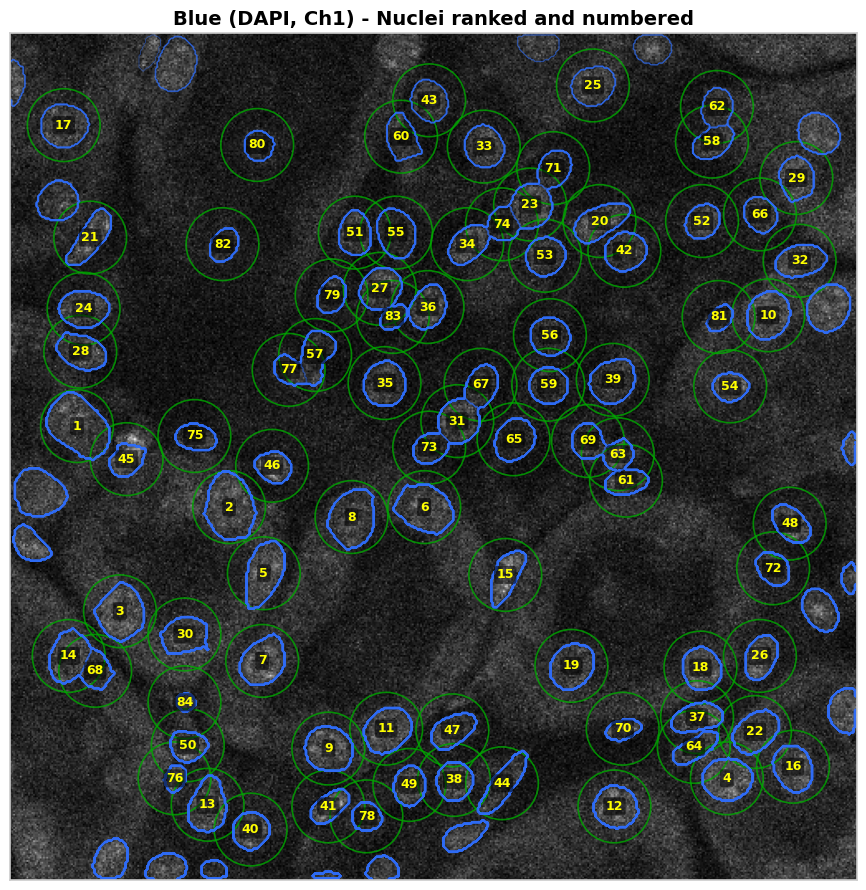


Usa la prossima cella: imposta MANUAL_PIVOT['pivot_label'] con il label del nucleo che vuoi analizzare.


In [ ]:
# %% [markdown]
# # Quantitative Z-Stack Analysis: Step 1/2 - Nuclei ranking on Blue (DAPI, Ch1)
# Pipeline: AI Segmentation (Cellpose) -> Candidate ranking -> Numbered overlay
# %

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec
from matplotlib.patches import Circle
from skimage import io, measure, morphology
import os
from pathlib import Path

from IPython.display import display
from cellpose import models

CONFIG = {
    "folder_path": "/Users/francesco/Repositories /CNR_SNR_3channels",
    "file_ch1": "zstack_150mic_50piani_10ripetizioni_50mW_512px_770nm_Ch1.tif",
    "file_ch2": "zstack_150mic_50piani_10ripetizioni_50mW_512px_770nm_Ch2.tif",
    "file_ch3": "zstack_150mic_50piani_10ripetizioni_50mW_512px_770nm_Ch3.tif",
    "nomi_canali": ["Blue (DAPI, Ch1)", "Green (Ch2)", "Red (Ch3)"],
    "z_target": 11,
    "cmap_visual": "gray",

    # Signal ROI
    "roi_radius": 22,
    "bordo_sicurezza": 30,

    # Pivot selection: auto | ranked_choice | interactive_choice | manual_label | manual_coords
    "pivot_mode": "manual_label",
    "pivot_rank": 1,
    "pivot_label": 1,
    "pivot_cx": 256,
    "pivot_cy": 256,

    # Local background ROI search
    "bg_radius": 18,
    "bg_search_rmin": 40,
    "bg_search_rmax": 120,
    "bg_step": 4,
    "bg_exclusion_margin": 6,

    # BG selection: auto | ranked_choice | interactive_choice
    "bg_mode": "auto",
    "bg_rank": 1,

    # Number of rows shown in candidate tables
    "show_top_n_candidates": 12,
}

def estrai_slice_2d(stack, z_target):
    if stack.ndim == 3:
        z_index = min(max(z_target, 0), stack.shape[0] - 1)
        return stack[z_index, :, :]
    return stack

def crea_maschera_circolare(shape, cx, cy, r):
    h, w = shape
    y_grid, x_grid = np.ogrid[:h, :w]
    return (x_grid - cx) ** 2 + (y_grid - cy) ** 2 <= r ** 2

def estrai_crop(immagine_2d, cx, cy, r):
    h, w = immagine_2d.shape
    y_min, y_max = max(0, cy - r), min(h, cy + r)
    x_min, x_max = max(0, cx - r), min(w, cx + r)
    crop_img = immagine_2d[y_min:y_max, x_min:x_max]
    return crop_img, (cx - x_min, cy - y_min)

def chiedi_rank_interattivo(prompt, max_rank, default_rank):
    default_rank = int(default_rank)
    msg = f"{prompt} [1-{max_rank}] (default={default_rank}): "
    valore = input(msg).strip()
    if valore == "":
        return default_rank
    rank = int(valore)
    if rank < 1 or rank > max_rank:
        raise ValueError(f"Rank must be in [1, {max_rank}], got {rank}.")
    return rank

def segmenta_nuclei(immagine_2d, config):
    print("- Starting Cellpose neural network (model_type='nuclei')...")
    model = models.CellposeModel(gpu=False, model_type='nuclei')
    eval_result = model.eval(immagine_2d, diameter=None, channels=[0, 0])
    masks = eval_result[0] if isinstance(eval_result, tuple) else eval_result
    regioni = measure.regionprops(masks, intensity_image=immagine_2d)
    return masks, regioni

def trova_nucleo_auto(regioni, immagine_shape, config):
    candidati = []
    h, w = immagine_shape
    b = config["bordo_sicurezza"]

    for reg in regioni:
        cy, cx = reg.centroid
        if cy < b or cy > h - b or cx < b or cx > w - b:
            continue

        score = float(reg.area) * float(reg.intensity_mean)
        candidati.append(
            {
                "label": int(reg.label),
                "cx": int(cx),
                "cy": int(cy),
                "score": score,
            }
        )

    if candidati:
        migliore = max(candidati, key=lambda item: item["score"])
        return migliore["cx"], migliore["cy"], config["roi_radius"], migliore["label"], candidati

    print("! WARNING: Cellpose did not find any valid nuclei.")
    return w // 2, h // 2, config["roi_radius"], None, []

def trova_nucleo_label(regioni, label_target, config):
    for reg in regioni:
        if int(reg.label) == int(label_target):
            cy, cx = reg.centroid
            return int(cx), int(cy), config["roi_radius"], int(reg.label)
    raise ValueError(f"Pivot label {label_target} not found in Cellpose segmentation.")

def tabella_candidati_nuclei(candidati):
    if not candidati:
        return pd.DataFrame()
    df = pd.DataFrame(candidati).sort_values("score", ascending=False).reset_index(drop=True)
    df.insert(0, "Rank", np.arange(1, len(df) + 1))
    return df[["Rank", "label", "cx", "cy", "score"]]

def scegli_nucleo_da_rank(candidati, rank, config):
    df = tabella_candidati_nuclei(candidati)
    if df.empty:
        raise RuntimeError("No nucleus candidates available for ranked choice.")

    rank = int(rank)
    if rank < 1 or rank > len(df):
        raise ValueError(f"pivot_rank must be in [1, {len(df)}], got {rank}.")

    r = df.iloc[rank - 1]
    return int(r["cx"]), int(r["cy"]), int(config["roi_radius"]), int(r["label"])

def seleziona_nucleo_pivot(immagine_2d, masks, regioni, config):
    pivot_mode = config["pivot_mode"]
    candidati = []

    if pivot_mode in ["auto", "ranked_choice", "interactive_choice"]:
        _, _, _, _, candidati = trova_nucleo_auto(regioni, immagine_2d.shape, config)
        if pivot_mode == "auto":
            cx, cy, r, label, _ = trova_nucleo_auto(regioni, immagine_2d.shape, config)
            sorgente = "auto"
        elif pivot_mode == "ranked_choice":
            cx, cy, r, label = scegli_nucleo_da_rank(candidati, config["pivot_rank"], config)
            sorgente = f"ranked_choice={config['pivot_rank']}"
        else:
            rank = chiedi_rank_interattivo("Select nucleus Rank", len(candidati), config["pivot_rank"])
            cx, cy, r, label = scegli_nucleo_da_rank(candidati, rank, config)
            sorgente = f"interactive_choice={rank}"
    elif pivot_mode == "manual_label":
        cx, cy, r, label = trova_nucleo_label(regioni, config["pivot_label"], config)
        sorgente = f"manual_label={label}"
    elif pivot_mode == "manual_coords":
        cx = int(config["pivot_cx"])
        cy = int(config["pivot_cy"])
        r = int(config["roi_radius"])
        label = int(masks[cy, cx]) if 0 <= cy < masks.shape[0] and 0 <= cx < masks.shape[1] else 0
        sorgente = f"manual_coords=({cx}, {cy})"
    else:
        raise ValueError("pivot_mode must be one of: auto, ranked_choice, interactive_choice, manual_label, manual_coords")

    return cx, cy, r, label, candidati, sorgente

def trova_bg_roi_locale(immagine_ref, masks, cx_signal, cy_signal, config):
    h, w = immagine_ref.shape
    bg_radius = config["bg_radius"]
    rmin = config["bg_search_rmin"]
    rmax = config["bg_search_rmax"]
    step = config["bg_step"]
    margin = config["bg_exclusion_margin"]

    masks_bool = masks > 0
    exclusion_mask = morphology.binary_dilation(masks_bool, morphology.disk(margin))
    signal_guard = crea_maschera_circolare((h, w), cx_signal, cy_signal, config["roi_radius"] + margin)
    forbidden = exclusion_mask | signal_guard

    candidati_bg = []

    for cy in range(bg_radius, h - bg_radius, step):
        for cx in range(bg_radius, w - bg_radius, step):
            distanza = float(np.hypot(cx - cx_signal, cy - cy_signal))
            if distanza < rmin or distanza > rmax:
                continue

            bg_mask = crea_maschera_circolare((h, w), cx, cy, bg_radius)
            if np.any(forbidden[bg_mask]):
                continue

            bg_pixels = np.asarray(immagine_ref, dtype=float)[bg_mask]
            if bg_pixels.size == 0:
                continue

            mean_bg = float(np.mean(bg_pixels))
            std_bg = float(np.std(bg_pixels))
            score = mean_bg + 0.35 * std_bg + 0.02 * distanza
            candidati_bg.append(
                {
                    "cx": cx,
                    "cy": cy,
                    "score": score,
                    "mean": mean_bg,
                    "std": std_bg,
                    "distance": distanza,
                }
            )

    if not candidati_bg:
        raise RuntimeError(
            "Unable to find a clean local background ROI. "
            "Try increasing bg_search_rmax or reducing bg_exclusion_margin."
        )

    migliore_bg = min(candidati_bg, key=lambda item: item["score"])
    return migliore_bg["cx"], migliore_bg["cy"], bg_radius, migliore_bg, candidati_bg

def tabella_candidati_bg(candidati_bg):
    if not candidati_bg:
        return pd.DataFrame()
    df = pd.DataFrame(candidati_bg).sort_values("score", ascending=True).reset_index(drop=True)
    df.insert(0, "Rank", np.arange(1, len(df) + 1))
    return df[["Rank", "cx", "cy", "distance", "mean", "std", "score"]]

def scegli_bg_da_rank(candidati_bg, rank):
    df = tabella_candidati_bg(candidati_bg)
    if df.empty:
        raise RuntimeError("No BG candidates available for ranked choice.")

    rank = int(rank)
    if rank < 1 or rank > len(df):
        raise ValueError(f"bg_rank must be in [1, {len(df)}], got {rank}.")

    r = df.iloc[rank - 1]
    return int(r["cx"]), int(r["cy"])

def analizza_con_bg_locale(immagine_2d, cx_signal, cy_signal, r_signal, cx_bg, cy_bg, r_bg):
    signal_mask = crea_maschera_circolare(immagine_2d.shape, cx_signal, cy_signal, r_signal)
    bg_mask = crea_maschera_circolare(immagine_2d.shape, cx_bg, cy_bg, r_bg)

    signal_pixels_all = np.asarray(immagine_2d, dtype=float)[signal_mask]
    background_pixels = np.asarray(immagine_2d, dtype=float)[bg_mask]

    if signal_pixels_all.size == 0 or background_pixels.size == 0:
        return None

    soglia_alta = np.percentile(signal_pixels_all, 95)
    pixel_segnale = signal_pixels_all[signal_pixels_all > soglia_alta]

    if pixel_segnale.size == 0:
        return None

    I_t = float(np.mean(pixel_segnale))
    I_b = float(np.mean(background_pixels))
    sigma_b = float(np.std(background_pixels)) if background_pixels.size > 0 else np.nan
    contrasto = (I_t - I_b) / I_b if np.isfinite(I_b) and I_b > 0 else np.nan
    snr = I_t / sigma_b if np.isfinite(sigma_b) and sigma_b > 0 else np.nan
    cnr = (I_t - I_b) / sigma_b if np.isfinite(sigma_b) and sigma_b > 0 else np.nan

    signal_crop, signal_center_local = estrai_crop(immagine_2d, cx_signal, cy_signal, r_signal)
    bg_crop, bg_center_local = estrai_crop(immagine_2d, cx_bg, cy_bg, r_bg)

    return {
        "I_t": I_t,
        "I_b": I_b,
        "Sigma_b": sigma_b,
        "Contrasto": contrasto,
        "SNR": snr,
        "CNR": cnr,
        "signal_crop": signal_crop,
        "signal_center_local": signal_center_local,
        "bg_crop": bg_crop,
        "bg_center_local": bg_center_local,
    }

# ---------------- STEP 1: load + segment + rank nuclei on Blue (DAPI, Ch1) ----------------
os.chdir(CONFIG["folder_path"])
immagini_z = []

for fname in [CONFIG["file_ch1"], CONFIG["file_ch2"], CONFIG["file_ch3"]]:
    p = Path(fname)
    if not p.exists():
        raise FileNotFoundError(f"File not found: {p.absolute()}")
    stack = io.imread(p)
    immagini_z.append(estrai_slice_2d(stack, CONFIG["z_target"]))

maschera_ai, regioni = segmenta_nuclei(immagini_z[0], CONFIG)
_, _, _, _, candidati_auto = trova_nucleo_auto(regioni, immagini_z[0].shape, CONFIG)
df_nuclei = tabella_candidati_nuclei(candidati_auto)

if df_nuclei.empty:
    raise RuntimeError("No valid nuclei found after border filtering.")

print("\n--- Nucleus candidates (ranked) ---")
display(df_nuclei.head(int(CONFIG["show_top_n_candidates"])))

fig, ax = plt.subplots(1, 1, figsize=(9, 9), facecolor="white")
ax.imshow(immagini_z[0], cmap=CONFIG["cmap_visual"], origin="upper")
ax.set_title("Blue (DAPI, Ch1) - Nuclei ranked and numbered", fontsize=14, fontweight="bold")

livelli_maschera = np.unique(maschera_ai)
livelli_maschera = livelli_maschera[livelli_maschera > 0]
if len(livelli_maschera) > 0:
    ax.contour(maschera_ai, levels=livelli_maschera, colors=["#2f6df6"], linewidths=0.55, alpha=0.55)

for _, riga in df_nuclei.iterrows():
    cx_n, cy_n = int(riga["cx"]), int(riga["cy"])
    rank_n = int(riga["Rank"])
    ax.add_patch(Circle((cx_n, cy_n), CONFIG["roi_radius"], linewidth=1.2, edgecolor="#00aa00", facecolor="none", alpha=0.8))
    ax.text(
        cx_n,
        cy_n,
        str(rank_n),
        color="yellow",
        fontsize=9,
        fontweight="bold",
        ha="center",
        va="center",
        bbox=dict(facecolor="black", edgecolor="none", alpha=0.55, boxstyle="round,pad=0.2"),
    )

ax.set_xticks([])
ax.set_yticks([])
for spine in ax.spines.values():
    spine.set_edgecolor("#cccccc")
    spine.set_linewidth(1.2)

plt.tight_layout()
plt.show()

print("\nUsa la prossima cella: imposta MANUAL_PIVOT['pivot_label'] con il label del nucleo che vuoi analizzare.")

In [ ]:
# %% [markdown]
# # Quantitative Z-Stack Analysis: Step 2/2 - Manual nucleus selection + full analysis
# Scegli il nucleo con rank, label oppure con click sull'immagine DAPI e lancia analisi completa sui 3 canali
# %

import time

if "CONFIG" not in globals() or "immagini_z" not in globals() or "maschera_ai" not in globals() or "regioni" not in globals():
    raise RuntimeError("Esegui prima la cella precedente (Step 1/2).")

if "df_nuclei" not in globals() or df_nuclei.empty:
    raise RuntimeError("Nessuna tabella nuclei disponibile. Esegui nuovamente la cella Step 1/2.")

# ------- INPUT MANUALE -------
MANUAL_PIVOT = {
    "selection_mode": "rank",   # rank | click | label
    "pivot_rank": 9,             # usato se selection_mode='rank'
    "pivot_label": 9,            # usato se selection_mode='label' o fallback
    "bg_mode": "auto",          # auto | ranked_choice
    "bg_rank": 1,                # usato se bg_mode='ranked_choice'
    "use_global_bg": True,       # True: cerca BG globale su tutto il campione (fissato per tutti i nuclei)
    "fast_mode": True,           # True: accelera la ricerca BG (consigliato)
    "click_timeout_s": 120,      # timeout click in secondi
}

CONFIG["pivot_mode"] = "manual_label"
CONFIG["bg_mode"] = MANUAL_PIVOT["bg_mode"]
CONFIG["bg_rank"] = int(MANUAL_PIVOT["bg_rank"] )

if bool(MANUAL_PIVOT.get("fast_mode", True)):
    CONFIG["bg_step"] = max(int(CONFIG.get("bg_step", 4)), 8)
    CONFIG["bg_search_rmax"] = min(int(CONFIG.get("bg_search_rmax", 120)), 90)
    CONFIG["show_top_n_candidates"] = min(int(CONFIG.get("show_top_n_candidates", 12)), 6)
    print(f"- FAST MODE attivo: bg_step={CONFIG['bg_step']}, bg_search_rmax={CONFIG['bg_search_rmax']}")

def trova_bg_roi_globale(immagine_ref, masks, config):
    """Ricerca globale la migliore ROI BG su tutto il campione (non legata a nessun nucleo specifico)."""
    h, w = immagine_ref.shape
    bg_radius = config["bg_radius"]
    step = config["bg_step"]
    margin = config["bg_exclusion_margin"]

    masks_bool = masks > 0
    exclusion_mask = morphology.binary_dilation(masks_bool, morphology.disk(margin))

    candidati_bg = []

    for cy in range(bg_radius, h - bg_radius, step):
        for cx in range(bg_radius, w - bg_radius, step):
            bg_mask = crea_maschera_circolare((h, w), cx, cy, bg_radius)
            if np.any(exclusion_mask[bg_mask]):
                continue

            bg_pixels = np.asarray(immagine_ref, dtype=float)[bg_mask]
            if bg_pixels.size == 0:
                continue

            mean_bg = float(np.mean(bg_pixels))
            std_bg = float(np.std(bg_pixels))
            score = mean_bg + 0.5 * std_bg  # Privilegia uniformità su distanza
            candidati_bg.append({
                "cx": cx,
                "cy": cy,
                "score": score,
                "mean": mean_bg,
                "std": std_bg,
            })

    if not candidati_bg:
        raise RuntimeError("Unable to find a clean global background ROI.")

    migliore_bg = min(candidati_bg, key=lambda item: item["score"])
    return migliore_bg["cx"], migliore_bg["cy"], bg_radius, migliore_bg, candidati_bg

def scegli_label_da_click(dapi_img, nuclei_df, roi_radius):
    fig, ax = plt.subplots(1, 1, figsize=(9, 9), facecolor="white")
    ax.imshow(dapi_img, cmap=CONFIG["cmap_visual"], origin="upper")
    ax.set_title("Click vicino al nucleo da selezionare, poi chiudi la figura", fontsize=13, fontweight="bold")

    livelli_maschera = np.unique(maschera_ai)
    livelli_maschera = livelli_maschera[livelli_maschera > 0]
    if len(livelli_maschera) > 0:
        ax.contour(maschera_ai, levels=livelli_maschera, colors=["#2f6df6"], linewidths=0.5, alpha=0.5)

    for _, riga in nuclei_df.iterrows():
        cx_n, cy_n = int(riga["cx"]), int(riga["cy"] )
        rank_n = int(riga["Rank"])
        ax.add_patch(Circle((cx_n, cy_n), roi_radius, linewidth=1.1, edgecolor="#00aa00", facecolor="none", alpha=0.8))
        ax.text(
            cx_n,
            cy_n,
            str(rank_n),
            color="yellow",
            fontsize=9,
            fontweight="bold",
            ha="center",
            va="center",
            bbox=dict(facecolor="black", edgecolor="none", alpha=0.55, boxstyle="round,pad=0.2"),
        )

    ax.set_xticks([])
    ax.set_yticks([])
    plt.tight_layout()

    timeout_s = int(MANUAL_PIVOT.get("click_timeout_s", 120))
    print(f"- Clicca una volta sul nucleo desiderato (timeout: {timeout_s}s).")
    punti = plt.ginput(1, timeout=timeout_s)
    plt.close(fig)

    if not punti:
        return None, None, None

    x_click, y_click = punti[0]
    coords = nuclei_df[["cx", "cy"]].to_numpy(dtype=float)
    d2 = (coords[:, 0] - x_click) ** 2 + (coords[:, 1] - y_click) ** 2
    idx = int(np.argmin(d2))
    selezionato = nuclei_df.iloc[idx]

    return int(selezionato["label"]), int(selezionato["Rank"]), float(np.sqrt(d2[idx]))

selection_mode = str(MANUAL_PIVOT["selection_mode"]).strip().lower()
t0 = time.perf_counter()

if selection_mode == "rank":
    rank_target = int(MANUAL_PIVOT["pivot_rank"])
    if rank_target < 1 or rank_target > len(df_nuclei):
        raise ValueError(f"pivot_rank deve essere in [1, {len(df_nuclei)}], ricevuto {rank_target}.")
    r = df_nuclei.iloc[rank_target - 1]
    CONFIG["pivot_label"] = int(r["label"])
    print(f"- Rank selection: Rank {rank_target} -> Label {CONFIG['pivot_label']}")
elif selection_mode == "click":
    label_click, rank_click, dist_click = scegli_label_da_click(immagini_z[0], df_nuclei, CONFIG["roi_radius"])
    if label_click is not None:
        CONFIG["pivot_label"] = int(label_click)
        print(f"- Click selection: Rank {rank_click} | Label {label_click} | Distanza click-centro: {dist_click:.2f}px")
    else:
        CONFIG["pivot_label"] = int(MANUAL_PIVOT["pivot_label"])
        print("! Nessun click rilevato, uso pivot_label di fallback.")
elif selection_mode == "label":
    CONFIG["pivot_label"] = int(MANUAL_PIVOT["pivot_label"])
else:
    raise ValueError("selection_mode must be one of: rank, click, label.")

# Selezione nucleo pivot manuale (dal label finale)
cx_sig, cy_sig, r_sig, pivot_label = trova_nucleo_label(regioni, CONFIG["pivot_label"], CONFIG)
pivot_source = f"manual_label={pivot_label}"
print(f"- Pivot source: {pivot_source}")
print(f"- Selected nucleus ROI: Center (X:{cx_sig}, Y:{cy_sig}) | Radius: {r_sig}px | Label: {pivot_label}")

# Ricerca BG globale per ciascun canale (se use_global_bg=True)
use_global_bg = bool(MANUAL_PIVOT.get("use_global_bg", False))
global_bg_dict = {}  # Memorizza BG globali per ciascun canale

if use_global_bg:
    print("\n--- Global BG ROI search per channel (su tutto il campione) ---")
    for nome, img in zip(CONFIG["nomi_canali"], immagini_z):
        t_bg0 = time.perf_counter()
        cx_bg_global, cy_bg_global, r_bg, bg_choice_global, candidati_bg_global = trova_bg_roi_globale(
            img, maschera_ai, CONFIG
        )
        elapsed = time.perf_counter() - t_bg0
        global_bg_dict[nome] = {
            "cx": cx_bg_global,
            "cy": cy_bg_global,
            "r": r_bg,
            "candidati": candidati_bg_global,
        }
        print(f"- {nome}: Global BG Center (X:{cx_bg_global}, Y:{cy_bg_global}) | t={elapsed:.2f}s")

# Analisi quantitativa su tutti i canali
risultati_dati = []
analisi_canali = []

print("\n--- Quantitative Results with BG ROI ---")

for nome, img in zip(CONFIG["nomi_canali"], immagini_z):
    if use_global_bg:
        cx_bg = global_bg_dict[nome]["cx"]
        cy_bg = global_bg_dict[nome]["cy"]
        r_bg = global_bg_dict[nome]["r"]
        bg_source = "global"
    else:
        t_bg0 = time.perf_counter()
        cx_bg_auto, cy_bg_auto, r_bg, bg_choice, candidati_bg = trova_bg_roi_locale(
            img, maschera_ai, cx_sig, cy_sig, CONFIG
        )

        if CONFIG["bg_mode"] == "auto":
            cx_bg, cy_bg = cx_bg_auto, cy_bg_auto
            bg_source = "auto"
        elif CONFIG["bg_mode"] == "ranked_choice":
            cx_bg, cy_bg = scegli_bg_da_rank(candidati_bg, CONFIG["bg_rank"])
            bg_source = f"ranked_choice={CONFIG['bg_rank']}"
        else:
            raise ValueError("bg_mode must be one of: auto, ranked_choice")

        elapsed_bg = time.perf_counter() - t_bg0
        print(
            f"- {nome}: BG source={bg_source} | Center (X:{cx_bg}, Y:{cy_bg}) | "
            f"Candidates={len(candidati_bg)} | t={elapsed_bg:.2f}s"
        )

        df_bg = tabella_candidati_bg(candidati_bg)
        if not df_bg.empty:
            print(f"  Top BG candidates ({nome}):")
            display(df_bg.head(int(CONFIG["show_top_n_candidates"])))

    risultato = analizza_con_bg_locale(img, cx_sig, cy_sig, r_sig, cx_bg, cy_bg, r_bg)
    if risultato is None:
        raise RuntimeError(f"Analysis failed for channel {nome}.")

    risultato["bg_cx"] = int(cx_bg)
    risultato["bg_cy"] = int(cy_bg)
    risultato["bg_r"] = int(r_bg)
    risultato["bg_source"] = bg_source
    risultato["bg_candidates"] = int(len(global_bg_dict[nome]["candidati"])) if use_global_bg else int(len(candidati_bg))

    risultati_dati.append(
        (
            nome,
            risultato["I_t"],
            risultato["I_b"],
            risultato["Sigma_b"],
            risultato["Contrasto"],
            risultato["SNR"],
            risultato["CNR"],
        )
    )
    analisi_canali.append(risultato)

df_roi = pd.DataFrame(
    risultati_dati,
    columns=["Channel", "I_t (Signal)", "I_b (Local BG)", "Sigma_b", "Contrast", "SNR", "CNR"],
)
print("\n--- Quantitative Results with Local External BG ROI (per channel) ---")
display(df_roi.style.format(precision=2, na_rep="NaN").hide(axis="index"))

# Dashboard
fig = plt.figure(figsize=(18, 13), facecolor="white")

gs = gridspec.GridSpec(3, 3, figure=fig, hspace=0.18, wspace=0.15, left=0.04, right=0.98, top=0.90, bottom=0.04)

livelli_maschera = np.unique(maschera_ai)
livelli_maschera = livelli_maschera[livelli_maschera > 0]

for i in range(3):
    risultato = analisi_canali[i]

    ax_raw = fig.add_subplot(gs[0, i])
    ax_raw.imshow(immagini_z[i], cmap=CONFIG["cmap_visual"], origin="upper")
    ax_raw.set_title(CONFIG["nomi_canali"][i], color="black", fontsize=15, fontweight="bold", pad=10)

    if i == 0 and len(livelli_maschera) > 0:
        ax_raw.contour(maschera_ai, levels=livelli_maschera, colors=["#4444ff"], linewidths=0.5, alpha=0.6)

    ax_raw.add_patch(Circle((cx_sig, cy_sig), r_sig, linewidth=2, edgecolor="#2ca02c", facecolor="none", linestyle="--"))
    ax_raw.add_patch(
        Circle(
            (risultato["bg_cx"], risultato["bg_cy"]),
            risultato["bg_r"],
            linewidth=2,
            edgecolor="#1f77b4",
            facecolor="none",
            linestyle=":",
        )
    )

    ax_signal = fig.add_subplot(gs[1, i])
    ax_signal.imshow(risultato["signal_crop"], cmap=CONFIG["cmap_visual"], origin="upper")
    ax_signal.add_patch(Circle(risultato["signal_center_local"], r_sig, linewidth=2, edgecolor="#2ca02c", facecolor="none"))

    stats_text = (
        f" ROI STATISTICS \n"
        f"------------------\n"
        f"Signal (I_t) : {risultato['I_t']:.1f}\n"
        f"Local BG(I_b): {risultato['I_b']:.1f}\n"
        f"BG StdDev    : {risultato['Sigma_b']:.2f}\n\n"
        f"CONTRAST     : {risultato['Contrasto']:.2f}\n"
        f"SNR          : {risultato['SNR']:.2f}\n"
        f"CNR          : {risultato['CNR']:.2f}"
    )
    ax_signal.text(
        0.04,
        0.05,
        stats_text,
        transform=ax_signal.transAxes,
        color="black",
        fontsize=10.5,
        va="bottom",
        fontfamily="monospace",
        bbox=dict(facecolor="white", edgecolor="#2ca02c", boxstyle="round,pad=0.6", alpha=0.92),
    )

    ax_bg = fig.add_subplot(gs[2, i])
    ax_bg.imshow(risultato["bg_crop"], cmap=CONFIG["cmap_visual"], origin="upper")
    ax_bg.add_patch(
        Circle(
            risultato["bg_center_local"],
            risultato["bg_r"],
            linewidth=2,
            edgecolor="#1f77b4",
            facecolor="none",
        )
    )
    ax_bg.set_title(
        f"Local external BG ROI ({risultato['bg_source']}, n={risultato['bg_candidates']})",
        color="black",
        fontsize=12,
        pad=8,
    )

for ax in fig.axes:
    ax.set_xticks([])
    ax.set_yticks([])
    for spine in ax.spines.values():
        spine.set_edgecolor("#cccccc")
        spine.set_linewidth(1.5)

plt.show()
print(f"- Tempo totale cella 10: {time.perf_counter() - t0:.2f} s")

RuntimeError: Esegui prima la cella precedente (Step 1/2).

=== ANALISI DAPI MULTI-NUCLEO (ROI CELLPOSE) ===
Nuclei segmentati da Cellpose: 105
Nuclei validi analizzati: 88
Segnale = media dei pixel nucleari >= P80
Background = anello esterno alla ROI, fuori da tutte le maschere, limitato ai pixel <= P35

--- Riassunto metriche (media, dispersione ed errore indicativo) ---
  Metrica  N  Media   Std   SEM  CI95
      I_t 88 16.810 3.260 0.348 0.681
      I_b 88  3.336 0.867 0.092 0.181
  Sigma_b 88  1.199 0.202 0.022 0.042
Contrasto 88  4.247 1.242 0.132 0.259
      SNR 88 11.455 2.768 0.295 0.578


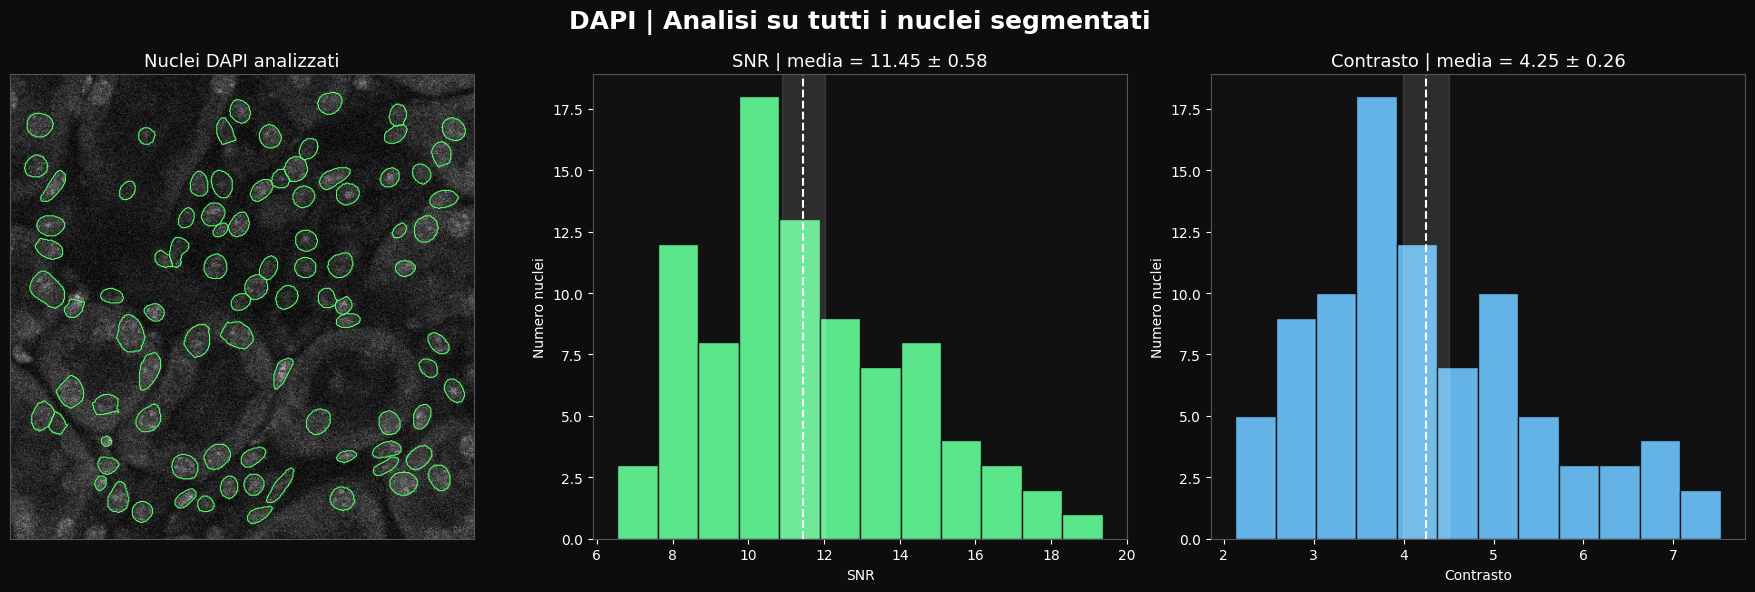

,Label,Area_px,Centroid_X,Centroid_Y,I_t,I_b,Sigma_b,Contrasto,SNR,N_pixel_nucleo,N_pixel_background
0,97,310,192.8,467.1,22.947,3.055,1.027,6.512,19.365,310,585
1,32,502,223.6,154.1,18.010,2.112,0.901,7.528,17.641,502,537
2,58,318,159.0,261.8,22.062,2.877,1.103,6.668,17.395,318,822
3,85,200,370.3,420.6,22.071,2.740,1.131,7.054,17.085,200,674
4,34,451,252.3,165.3,17.592,2.077,0.924,7.469,16.799,451,738
5,56,256,367.5,254.6,20.710,2.874,1.085,6.207,16.432,256,593
6,24,467,48.2,123.3,20.351,2.900,1.083,6.018,16.110,467,878
7,50,528,271.0,234.1,16.178,2.099,0.895,6.707,15.737,528,707
8,95,570,119.1,466.8,19.182,2.939,1.054,5.526,15.404,570,676
9,38,179,231.6,171.2,16.188,2.118,0.920,6.642,15.289,179,389


In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from skimage import measure, morphology

if "immagini_z" not in globals() or "maschera_ai" not in globals():
    raise RuntimeError("Esegui prima la cella ROI Cellpose per creare immagini_z e maschera_ai.")

dapi_img = np.asarray(immagini_z[0], dtype=float)
masks = np.asarray(maschera_ai)

PARAMS_MULTI_NUCLEI = {
    "signal_percentile": 80,
    "background_percentile": 35,
    "annulus_inner_px": 4,
    "annulus_outer_px": 18,
    "min_nucleus_area": 40,
    "min_background_pixels": 80,
    "edge_margin_px": 20,
}


def analizza_nucleo_dapi(image, masks, label, params):
    nucleus_mask = masks == label
    nucleus_pixels = image[nucleus_mask]

    if nucleus_pixels.size == 0:
        return None

    inner_ring = morphology.dilation(nucleus_mask, morphology.disk(params["annulus_inner_px"]))
    outer_ring = morphology.dilation(nucleus_mask, morphology.disk(params["annulus_outer_px"]))
    background_mask = outer_ring & ~inner_ring & (masks == 0)
    background_pixels = image[background_mask]

    if background_pixels.size < params["min_background_pixels"]:
        return None

    signal_threshold = np.percentile(nucleus_pixels, params["signal_percentile"])
    signal_pixels = nucleus_pixels[nucleus_pixels >= signal_threshold]

    background_threshold = np.percentile(background_pixels, params["background_percentile"])
    background_pixels = background_pixels[background_pixels <= background_threshold]

    if signal_pixels.size == 0 or background_pixels.size < max(20, params["min_background_pixels"] // 3):
        return None

    I_t = float(np.mean(signal_pixels))
    I_b = float(np.mean(background_pixels))
    sigma_b = float(np.std(background_pixels, ddof=1)) if background_pixels.size > 1 else np.nan
    contrasto = (I_t - I_b) / I_b if np.isfinite(I_b) and I_b > 0 else np.nan
    snr = (I_t - I_b) / sigma_b if np.isfinite(sigma_b) and sigma_b > 0 else np.nan

    return {
        "I_t": I_t,
        "I_b": I_b,
        "Sigma_b": sigma_b,
        "Contrasto": contrasto,
        "SNR": snr,
        "N_pixel_nucleo": int(nucleus_pixels.size),
        "N_pixel_background": int(background_pixels.size),
    }


props = measure.regionprops(masks, intensity_image=dapi_img)
righe = []
label_validi = []

for reg in props:
    cy, cx = reg.centroid
    if reg.area < PARAMS_MULTI_NUCLEI["min_nucleus_area"]:
        continue
    if (
        cy < PARAMS_MULTI_NUCLEI["edge_margin_px"]
        or cy > dapi_img.shape[0] - PARAMS_MULTI_NUCLEI["edge_margin_px"]
        or cx < PARAMS_MULTI_NUCLEI["edge_margin_px"]
        or cx > dapi_img.shape[1] - PARAMS_MULTI_NUCLEI["edge_margin_px"]
    ):
        continue

    stats = analizza_nucleo_dapi(dapi_img, masks, reg.label, PARAMS_MULTI_NUCLEI)
    if stats is None or not np.isfinite(stats["SNR"]) or not np.isfinite(stats["Contrasto"]):
        continue

    righe.append(
        {
            "Label": reg.label,
            "Area_px": int(reg.area),
            "Centroid_X": round(cx, 1),
            "Centroid_Y": round(cy, 1),
            **stats,
        }
    )
    label_validi.append(reg.label)

df_nuclei_dapi = pd.DataFrame(righe).sort_values("SNR", ascending=False).reset_index(drop=True)

if df_nuclei_dapi.empty:
    raise RuntimeError("Nessun nucleo valido trovato con i criteri correnti. Prova ad allargare l'anello di background o ridurre i filtri.")


def riassunto_metriche(df, colonne):
    summary_rows = []
    for col in colonne:
        values = df[col].dropna().to_numpy(dtype=float)
        n = values.size
        media = float(np.mean(values))
        std = float(np.std(values, ddof=1)) if n > 1 else 0.0
        sem = std / np.sqrt(n) if n > 1 else 0.0
        ci95 = 1.96 * sem if n > 1 else 0.0
        summary_rows.append(
            {
                "Metrica": col,
                "N": int(n),
                "Media": media,
                "Std": std,
                "SEM": sem,
                "CI95": ci95,
            }
        )
    return pd.DataFrame(summary_rows)


df_summary_dapi = riassunto_metriche(df_nuclei_dapi, ["I_t", "I_b", "Sigma_b", "Contrasto", "SNR"])

print("=== ANALISI DAPI MULTI-NUCLEO (ROI CELLPOSE) ===")
print(f"Nuclei segmentati da Cellpose: {len(props)}")
print(f"Nuclei validi analizzati: {len(df_nuclei_dapi)}")
print("Segnale = media dei pixel nucleari >= P80")
print("Background = anello esterno alla ROI, fuori da tutte le maschere, limitato ai pixel <= P35")
print("\n--- Riassunto metriche (media, dispersione ed errore indicativo) ---")
print(df_summary_dapi.round(3).to_string(index=False))

fig, axes = plt.subplots(1, 3, figsize=(18, 6), facecolor="#0d0d0d")
fig.suptitle("DAPI | Analisi su tutti i nuclei segmentati", color="white", fontsize=18, fontweight="bold")

axes[0].imshow(dapi_img, cmap="gray", origin="upper")
axes[0].set_title("Nuclei DAPI analizzati", color="white", fontsize=13)
for label in label_validi:
    axes[0].contour(masks == label, levels=[0.5], colors=["#4dff65"], linewidths=0.8)

snr_mean = df_summary_dapi.loc[df_summary_dapi["Metrica"] == "SNR", "Media"].iloc[0]
snr_ci95 = df_summary_dapi.loc[df_summary_dapi["Metrica"] == "SNR", "CI95"].iloc[0]
axes[1].hist(df_nuclei_dapi["SNR"], bins=12, color="#65ff9a", edgecolor="#0d0d0d", alpha=0.9)
axes[1].axvline(snr_mean, color="white", linestyle="--", linewidth=1.5)
axes[1].axvspan(snr_mean - snr_ci95, snr_mean + snr_ci95, color="white", alpha=0.12)
axes[1].set_title(f"SNR | media = {snr_mean:.2f} ± {snr_ci95:.2f}", color="white", fontsize=13)
axes[1].set_xlabel("SNR", color="white")
axes[1].set_ylabel("Numero nuclei", color="white")

contrast_mean = df_summary_dapi.loc[df_summary_dapi["Metrica"] == "Contrasto", "Media"].iloc[0]
contrast_ci95 = df_summary_dapi.loc[df_summary_dapi["Metrica"] == "Contrasto", "CI95"].iloc[0]
axes[2].hist(df_nuclei_dapi["Contrasto"], bins=12, color="#6ec6ff", edgecolor="#0d0d0d", alpha=0.9)
axes[2].axvline(contrast_mean, color="white", linestyle="--", linewidth=1.5)
axes[2].axvspan(contrast_mean - contrast_ci95, contrast_mean + contrast_ci95, color="white", alpha=0.12)
axes[2].set_title(f"Contrasto | media = {contrast_mean:.2f} ± {contrast_ci95:.2f}", color="white", fontsize=13)
axes[2].set_xlabel("Contrasto", color="white")
axes[2].set_ylabel("Numero nuclei", color="white")

for ax in axes:
    ax.set_facecolor("#111111")
    ax.tick_params(colors="white")
    for spine in ax.spines.values():
        spine.set_color("#555555")
    if ax is axes[0]:
        ax.set_xticks([])
        ax.set_yticks([])

plt.tight_layout()
plt.show()

df_nuclei_dapi.head(10).round(3)

model_type argument is not used in v4.0.1+. Ignoring this argument...


DAPI: zstack_150mic_50piani_10ripetizioni_50mW_512px_770nm_Ch1.tif | shape=(50, 512, 512), dtype=int16
GREEN: zstack_150mic_50piani_10ripetizioni_50mW_512px_770nm_Ch2.tif | shape=(50, 512, 512), dtype=int16
RED: zstack_150mic_50piani_10ripetizioni_50mW_512px_770nm_Ch3.tif | shape=(50, 512, 512), dtype=int16


channels deprecated in v4.0.1+. If data contain more than 3 channels, only the first 3 channels will be used
/opt/homebrew/lib/python3.14/site-packages/cellpose/dynamics.py:524: UserWarning: Sparse invariant checks are implicitly disabled. Memory errors (e.g. SEGFAULT) will occur when operating on a sparse tensor which violates the invariants, but checks incur performance overhead. To silence this warning, explicitly opt in or out. See `torch.sparse.check_sparse_tensor_invariants.__doc__` for guidance.  (Triggered internally at /Users/runner/work/pytorch/pytorch/pytorch/aten/src/ATen/Context.cpp:767.)
  coo = torch.sparse_coo_tensor(pt, torch.ones(pt.shape[1], device=pt.device, dtype=torch.int),
/var/folders/gj/gl2kb7qs563ckkg3vvvr7dvh0000gn/T/ipykernel_53988/2943758172.py:64: FutureWarning: `binary_dilation` is deprecated since version 0.26 and will be removed in version 0.28. Use `skimage.morphology.dilation` instead. Note the lack of mirroring for non-symmetric footprints (see docst

Nuclei rilevati: 120
Nuclei analizzati: 97/120 (80.8% passati i filtri)


,mean,std,min,max
DAPI_SNR,16.443,5.013,9.019,30.056
GREEN_SNR,9.250,7.448,0.599,38.655
RED_SNR,8.600,5.297,0.891,24.833
Ratio_G_R,2.484,1.071,0.786,5.358
Pearson_GR,0.634,0.173,0.192,0.894


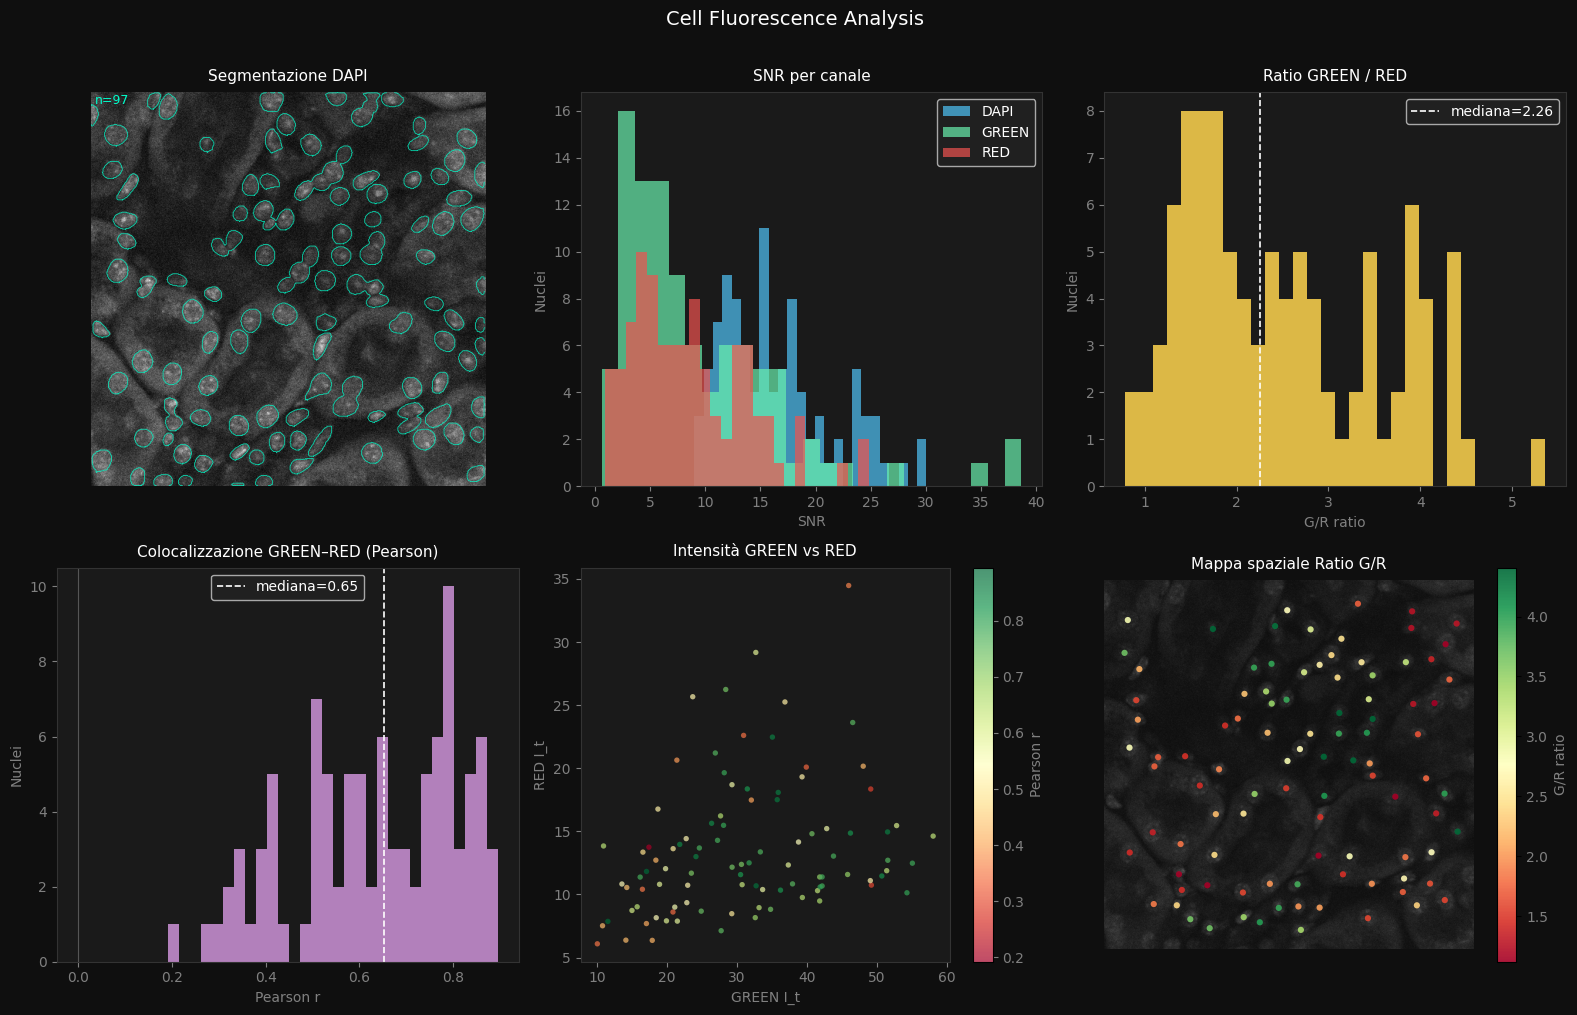

In [ ]:
# %% ================== IMPORT ================== #PERO QUESTO è SU UN CANALE SOLO, OVVERO DAPI, PERCHé CELLPOSE è STATO USATO SOLO SU QUEL CANALE PER TROVARE I NUCLEI. LA PARTE SUCCESSIVA è QUINDI DA ADATTARE PER ANALIZZARE ANCHE GLI ALTRI CANALI IN BASE A QUESTE MASCHERE DI NUCLEO ALTRIMENTI SEMBRA CHE IL SNR ECC è QUELLO TOTALE MA INVECE è RELATIVO AL CANALE 1 E QUINDI AL PMT1 MA BISOGNA FARLO OGNUNO PER CIASCUN CANALE ECC
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path
from skimage import io, measure, morphology, color
from cellpose import models

# %% ================== CONFIG ==================
CONFIG = {
    "folder_path": "/Users/francesco/Repositories /CNR_SNR_3channels",
    "files": {
        "DAPI":  "zstack_150mic_50piani_10ripetizioni_50mW_512px_770nm_Ch1.tif",
        "GREEN": "zstack_150mic_50piani_10ripetizioni_50mW_512px_770nm_Ch2.tif",
        "RED":   "zstack_150mic_50piani_10ripetizioni_50mW_512px_770nm_Ch3.tif",
    },
    "z_mode":    "mean",   # "single" | "mean" | "max"
    "z_target":  10,
    "z_window":  2,

    "min_area":    50,
    "edge_margin": 20,

    "signal_percentile":     90,
    "background_percentile": 30,
    "annulus_inner":          3,
    "annulus_outer":         15,
}

# %% ================== Z-PROCESS ==================
def extract_z(img_stack, cfg):
    if img_stack.ndim != 3:
        return img_stack.astype(float)
    z, w = cfg["z_target"], cfg["z_window"]
    z_lo = max(0, z - w)
    z_hi = min(img_stack.shape[0], z + w + 1)
    if cfg["z_mode"] == "single":
        return img_stack[min(z, img_stack.shape[0]-1)].astype(float)
    elif cfg["z_mode"] == "mean":
        return np.mean(img_stack[z_lo:z_hi], axis=0)
    elif cfg["z_mode"] == "max":
        return np.max(img_stack[z_lo:z_hi], axis=0)
    else:
        raise ValueError(f"z_mode non valido: {cfg['z_mode']}")

# %% ================== LOAD ==================
images = {}
folder = Path(CONFIG["folder_path"])
for k, path in CONFIG["files"].items():
    full_path = folder / path
    if not full_path.exists():
        raise FileNotFoundError(f"File non trovato: {full_path}")
    stack = io.imread(full_path)
    images[k] = extract_z(stack, CONFIG)
    print(f"{k}: {full_path.name} | shape={stack.shape}, dtype={stack.dtype}")

# %% ================== CELLPOSE ==================
model = models.CellposeModel(gpu=False, model_type="nuclei")
masks, *_ = model.eval(images["DAPI"], channels=[0, 0])
print(f"Nuclei rilevati: {masks.max()}")

# %% ================== FUNZIONI ==================
def get_background_mask(nucleus, masks, cfg):
    dil_all = morphology.binary_dilation(masks > 0, morphology.disk(3))
    inner   = morphology.binary_dilation(nucleus, morphology.disk(cfg["annulus_inner"]))
    outer   = morphology.binary_dilation(nucleus, morphology.disk(cfg["annulus_outer"]))
    return outer & ~inner & ~dil_all

def compute_channel_metrics(nuc_pix, bkg_pix, cfg, ch):
    if len(bkg_pix) < 30:
        return None
    s_thr      = np.percentile(nuc_pix, cfg["signal_percentile"])
    b_thr      = np.percentile(bkg_pix, cfg["background_percentile"])
    signal     = nuc_pix[nuc_pix >= s_thr]
    background = bkg_pix[bkg_pix <= b_thr]
    if len(signal) == 0 or len(background) < 20:
        return None
    I_t, I_b, sigma_b = signal.mean(), background.mean(), background.std()
    return {
        f"{ch}_I_t":      I_t,
        f"{ch}_I_b":      I_b,
        f"{ch}_SNR":      (I_t - I_b) / (sigma_b + 1e-6),
        f"{ch}_Contrast": (I_t - I_b) / (I_b + 1e-6),
    }

def compute_colocalization(images, nucleus):
    g, r = images["GREEN"][nucleus], images["RED"][nucleus]
    return float(np.corrcoef(g, r)[0, 1]) if len(g) > 10 else np.nan

def analyze_nucleus(label, masks, images, cfg):
    nucleus = masks == label
    if nucleus.sum() < cfg["min_area"]:
        return None
    y, x = np.where(nucleus)
    cy, cx = y.mean(), x.mean()
    m = cfg["edge_margin"]
    if cy < m or cy > masks.shape[0]-m or cx < m or cx > masks.shape[1]-m:
        return None
    bkg_mask = get_background_mask(nucleus, masks, cfg)
    results  = {"Label": label, "Area": int(nucleus.sum()), "CentroidY": cy, "CentroidX": cx}
    for ch, img in images.items():
        metrics = compute_channel_metrics(img[nucleus], img[bkg_mask], cfg, ch)
        if metrics is None:
            return None
        results.update(metrics)
    results["Pearson_GR"] = compute_colocalization(images, nucleus)
    results["Ratio_G_R"]  = results["GREEN_I_t"] / (results["RED_I_t"] + 1e-6)
    return results

# %% ================== LOOP ==================
props = measure.regionprops(masks)
data  = [res for reg in props
         if (res := analyze_nucleus(reg.label, masks, images, CONFIG)) is not None]

df = pd.DataFrame(data)
n_raw, n_analyzed = int(masks.max()), len(df)
print(f"Nuclei analizzati: {n_analyzed}/{n_raw} ({n_analyzed/n_raw*100:.1f}% passati i filtri)")

# %% ================== SUMMARY TABLE ==================
cols = ["DAPI_SNR", "GREEN_SNR", "RED_SNR", "Ratio_G_R", "Pearson_GR"]
display(df[cols].describe().T[["mean", "std", "min", "max"]].round(3))

# %% ================== VISUALIZZAZIONE ==================
fig, axes = plt.subplots(2, 3, figsize=(16, 10))
fig.patch.set_facecolor("#0f0f0f")

def style_ax(ax, title):
    ax.set_facecolor("#1a1a1a")
    ax.set_title(title, color="white", fontsize=11, pad=8)
    ax.tick_params(colors="gray")
    for spine in ax.spines.values():
        spine.set_edgecolor("#333")

# normalizza DAPI per visualizzazione
dapi_norm = images["DAPI"] - images["DAPI"].min()
dapi_norm = dapi_norm / (dapi_norm.max() + 1e-6)

# --- 1. Overlay segmentazione ---
ax = axes[0, 0]
style_ax(ax, "Segmentazione DAPI")
ax.imshow(dapi_norm, cmap="gray")
for cnt in measure.find_contours(masks > 0, 0.5):
    ax.plot(cnt[:, 1], cnt[:, 0], lw=0.6, color="#00ffcc", alpha=0.8)
ax.text(5, 15, f"n={n_analyzed}", color="#00ffcc", fontsize=9)
ax.axis("off")

# --- 2. SNR tutti i canali ---
ax = axes[0, 1]
style_ax(ax, "SNR per canale")
for ch, col in [("DAPI", "#4fc3f7"), ("GREEN", "#69f0ae"), ("RED", "#ef5350")]:
    ax.hist(df[f"{ch}_SNR"], bins=25, alpha=0.7, color=col, label=ch, edgecolor="none")
ax.set_xlabel("SNR", color="gray"); ax.set_ylabel("Nuclei", color="gray")
ax.legend(facecolor="#222", labelcolor="white", framealpha=0.8)

# --- 3. Ratio G/R ---
ax = axes[0, 2]
style_ax(ax, "Ratio GREEN / RED")
ax.hist(df["Ratio_G_R"], bins=30, color="#ffd54f", edgecolor="none", alpha=0.85)
med = df["Ratio_G_R"].median()
ax.axvline(med, color="white", ls="--", lw=1.2, label=f"mediana={med:.2f}")
ax.set_xlabel("G/R ratio", color="gray"); ax.set_ylabel("Nuclei", color="gray")
ax.legend(facecolor="#222", labelcolor="white", framealpha=0.8)

# --- 4. Pearson ---
ax = axes[1, 0]
style_ax(ax, "Colocalizzazione GREEN–RED (Pearson)")
p = df["Pearson_GR"].dropna()
ax.hist(p, bins=30, color="#ce93d8", edgecolor="none", alpha=0.85)
ax.axvline(0, color="#555", lw=0.8)
ax.axvline(p.median(), color="white", ls="--", lw=1.2, label=f"mediana={p.median():.2f}")
ax.set_xlabel("Pearson r", color="gray"); ax.set_ylabel("Nuclei", color="gray")
ax.legend(facecolor="#222", labelcolor="white", framealpha=0.8)

# --- 5. Scatter GREEN vs RED ---
ax = axes[1, 1]
style_ax(ax, "Intensità GREEN vs RED")
sc = ax.scatter(df["GREEN_I_t"], df["RED_I_t"],
                c=df["Pearson_GR"], cmap="RdYlGn",
                s=15, alpha=0.7, linewidths=0)
cbar = plt.colorbar(sc, ax=ax)
cbar.set_label("Pearson r", color="gray")
cbar.ax.yaxis.set_tick_params(color="gray")
plt.setp(cbar.ax.yaxis.get_ticklabels(), color="gray")
ax.set_xlabel("GREEN I_t", color="gray"); ax.set_ylabel("RED I_t", color="gray")

# --- 6. Mappa spaziale ---
ax = axes[1, 2]
style_ax(ax, "Mappa spaziale Ratio G/R")
ax.imshow(dapi_norm, cmap="gray", alpha=0.35)
sc2 = ax.scatter(df["CentroidX"], df["CentroidY"],
                 c=df["Ratio_G_R"], cmap="RdYlGn", s=20, alpha=0.9, linewidths=0,
                 vmin=df["Ratio_G_R"].quantile(0.05),
                 vmax=df["Ratio_G_R"].quantile(0.95))
cbar2 = plt.colorbar(sc2, ax=ax)
cbar2.set_label("G/R ratio", color="gray")
plt.setp(cbar2.ax.yaxis.get_ticklabels(), color="gray")
ax.axis("off")

plt.suptitle("Cell Fluorescence Analysis", color="white", fontsize=14, y=1.01)
plt.tight_layout()
plt.show()